# Real vs. AI-Generated Music Detection: Main Pipeline

Deep learning pipeline that classifies 10-second music clips as real or AI-generated,
comparing three models (LSTM from scratch, PANNs Cnn14 transfer, MERT transfer) under a
cost-sensitive objective, then testing generalization on external data (GTZAN + FakeMusicCaps).

Starts from a prepared `clip_manifest.csv` (data preparation done in a separate notebook)
and covers dataset loading, models, training, hyperparameter search, evaluation and reporting.

**Running it:** built for Google Colab with a T4 GPU. Mount Google Drive and replace
`PROJECT_ROOT` in the paths with the Drive folder holding the datasets.

### Setup

In [ ]:
import os
import time
import json
import random
import shutil
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import torchaudio
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from tqdm import tqdm
from google.colab import drive

print("Imports done.")

Imports done.


In [ ]:
drive.mount('/content/drive', force_remount=True)

BASE_PATH = "/content/drive/MyDrive/PROJECT_ROOT/datasets"
CLIP_MANIFEST_PATH = os.path.join(BASE_PATH, "clip_manifest.csv")

TARGET_SR = 16000
N_MELS = 64
BATCH_SIZE = 16
NUM_WORKERS = 0

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {DEVICE}")

Mounted at /content/drive
Using device: cpu


## Block 3: Dataset / DataLoader — Song-Level Sampling

One shared, model-agnostic PyTorch `Dataset`. Groups clips by parent song
rather than treating all clips as independent — clips from the same song share
genre, production, and generator characteristics, so pooling all 177,855 clips
flat overstates independent examples (really ~9,879 songs).

Train: one random clip per song, resampled fresh each epoch. Val/test: one
fixed clip per song, so metrics don't fluctuate with which crop was drawn.

Augmentation (noise + bitrate) still applies on the fly, train split only.

In [ ]:
clip_df = pd.read_csv(CLIP_MANIFEST_PATH)
print(f"Loaded {len(clip_df)} clips.")
print(clip_df.groupby(['split', 'label']).size())

LABEL_TO_IDX = {"real": 0, "fake": 1}

mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=TARGET_SR, n_mels=N_MELS, n_fft=1024, hop_length=256
)
amplitude_to_db = torchaudio.transforms.AmplitudeToDB()


def add_noise(waveform, snr_db_range=(10, 30)):
    snr_db = random.uniform(*snr_db_range)
    signal_power = waveform.pow(2).mean()
    noise_power = signal_power / (10 ** (snr_db / 10))
    noise = torch.randn_like(waveform) * noise_power.sqrt()
    return waveform + noise


def apply_bitrate_variation(waveform, sr, low_khz=8, high_khz=16):
    target_khz = random.choice([low_khz, high_khz])
    target_sr = target_khz * 1000
    if target_sr >= sr:
        return waveform
    down = torchaudio.functional.resample(waveform, sr, target_sr)
    back = torchaudio.functional.resample(down, target_sr, sr)
    if back.shape[-1] < waveform.shape[-1]:
        back = torch.nn.functional.pad(back, (0, waveform.shape[-1] - back.shape[-1]))
    else:
        back = back[..., :waveform.shape[-1]]
    return back


song_groups = clip_df.groupby(['item_filepath', 'split', 'label'])['clip_filepath'].apply(list).reset_index()
print(f"\nTotal songs: {len(song_groups)}")
print(song_groups.groupby(['split', 'label']).size())

train_songs_df = song_groups[song_groups['split'] == 'train'].reset_index(drop=True)
val_songs_df = song_groups[song_groups['split'] == 'val'].reset_index(drop=True)
test_songs_df = song_groups[song_groups['split'] == 'test'].reset_index(drop=True)


class SongLevelDataset(Dataset):
    """One item per song. Train: random clip per call (varies per epoch).
    Val/test: fixed first clip, deterministic."""
    def __init__(self, songs_df, augment=False, deterministic=False):
        self.df = songs_df.reset_index(drop=True)
        self.augment = augment
        self.deterministic = deterministic

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        clip_paths = row['clip_filepath']
        chosen_clip = clip_paths[0] if self.deterministic else random.choice(clip_paths)

        waveform = None
        last_err = None
        for attempt in range(3):
            try:
                waveform, sr = torchaudio.load(chosen_clip)
                break
            except Exception as e:
                last_err = e
                time.sleep(0.5)
        if waveform is None:
            raise RuntimeError(f"Failed to load {chosen_clip}: {last_err}")

        if waveform.shape[0] > 1:
            waveform = waveform.mean(dim=0, keepdim=True)

        if self.augment:
            waveform = add_noise(waveform)
            waveform = apply_bitrate_variation(waveform, sr)

        spectrogram = amplitude_to_db(mel_transform(waveform))
        label = LABEL_TO_IDX[row['label']]

        return {
            "waveform": waveform.squeeze(0),
            "spectrogram": spectrogram.squeeze(0),
            "label": torch.tensor(label, dtype=torch.long),
        }


def collate_fn(batch):
    return {
        "waveform": torch.stack([b["waveform"] for b in batch]),
        "spectrogram": torch.stack([b["spectrogram"] for b in batch]),
        "label": torch.stack([b["label"] for b in batch]),
    }


val_dataset = SongLevelDataset(val_songs_df, augment=False, deterministic=True)
test_dataset = SongLevelDataset(test_songs_df, augment=False, deterministic=True)

val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, collate_fn=collate_fn)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, collate_fn=collate_fn)

print(f"\nval_loader:  {len(val_dataset)} songs, {len(val_loader)} batches")
print(f"test_loader: {len(test_dataset)} songs, {len(test_loader)} batches")

Loaded 177855 clips.
split  label
test   fake     10481
       real     16383
train  fake     48475
       real     75900
val    fake     10430
       real     16186
dtype: int64

Total songs: 9879
split  label
test   fake      732
       real      750
train  fake     3415
       real     3500
val    fake      732
       real      750
dtype: int64

val_loader:  1482 songs, 93 batches
test_loader: 1482 songs, 93 batches


## Block 4: Model Definitions

Three models sharing one interface: `forward(batch) -> logits`.

- **BaselineLSTM** — no pretrained backbone, trained from scratch.
- **MelCNN** — frozen PANNs **Cnn14_16k** backbone (matched to our 16kHz
  pipeline — the default PANNs checkpoint is 32kHz and would silently
  mismatch our data).
- **AttentionSequenceModel** — frozen MERT backbone (24kHz; resampled from
  our 16kHz clips on the fly).

In [ ]:
# --- MelCNN: Cnn14 architecture, reconfigured + weighted for 16kHz ---
!pip install -q panns-inference
!wget -q -nc -O /root/Cnn14_16k_mAP=0.438.pth https://zenodo.org/record/3987831/files/Cnn14_16k_mAP%3D0.438.pth

from panns_inference.models import Cnn14

PANNS_16K_CHECKPOINT = "/root/Cnn14_16k_mAP=0.438.pth"

class MelCNN(nn.Module):
    def __init__(self, num_classes=2, dropout=0.3, freeze_backbone=True, device=DEVICE):
        super().__init__()
        print(f"Initializing MelCNN with Cnn14 (16kHz config) (device={device})...")

        # Same Cnn14 class, reconfigured to match the 16kHz checkpoint's training setup
        self.backbone = Cnn14(
            sample_rate=16000, window_size=512, hop_size=160,
            mel_bins=64, fmin=50, fmax=8000, classes_num=527,
        )
        checkpoint = torch.load(PANNS_16K_CHECKPOINT, map_location=device)
        self.backbone.load_state_dict(checkpoint['model'])
        self.backbone = self.backbone.to(device)
        print("Cnn14 (16kHz) backbone loaded.")

        if freeze_backbone:
            for param in self.backbone.parameters():
                param.requires_grad = False
            self.backbone.eval()
            print("Backbone frozen.")

        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(2048, num_classes)
        self.freeze_backbone = freeze_backbone

    def forward(self, batch):
        device = next(self.parameters()).device
        waveform = batch["waveform"].to(device)
        if self.freeze_backbone:
            with torch.no_grad():
                output_dict = self.backbone(waveform, None)
        else:
            output_dict = self.backbone(waveform, None)
        return self.head(self.dropout(output_dict["embedding"]))

In [ ]:
class BaselineLSTM(nn.Module):
    def __init__(self, n_mels=64, hidden_dim=128, num_layers=2, num_classes=2, dropout=0.3):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_mels, hidden_size=hidden_dim, num_layers=num_layers,
            batch_first=True, dropout=dropout if num_layers > 1 else 0.0, bidirectional=False,
        )
        self.bn = nn.BatchNorm1d(hidden_dim)
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(hidden_dim, num_classes)

    def forward(self, batch):
        x = batch["spectrogram"].transpose(1, 2)
        _, (h_n, _) = self.lstm(x)
        last_hidden = self.bn(h_n[-1])
        last_hidden = self.dropout(last_hidden)
        return self.head(last_hidden)


# --- MelCNN: Cnn14 architecture, reconfigured + weighted for 16kHz ---
!pip install -q panns-inference
!wget -q -nc -O /root/Cnn14_16k_mAP=0.438.pth https://zenodo.org/record/3987831/files/Cnn14_16k_mAP%3D0.438.pth

from panns_inference.models import Cnn14

PANNS_16K_CHECKPOINT = "/root/Cnn14_16k_mAP=0.438.pth"

class MelCNN(nn.Module):
    def __init__(self, num_classes=2, dropout=0.3, freeze_backbone=True, device=DEVICE):
        super().__init__()
        print(f"Initializing MelCNN with Cnn14_16k (device={device})...")

        self.backbone = Cnn14(
            sample_rate=16000, window_size=512, hop_size=160,
            mel_bins=64, fmin=50, fmax=8000, classes_num=527,
        )
        checkpoint = torch.load(PANNS_16K_CHECKPOINT, map_location=device, weights_only=False)
        self.backbone.load_state_dict(checkpoint['model'])
        self.backbone = self.backbone.to(device)
        print("Cnn14_16k backbone loaded and matched to 16kHz.")

        if freeze_backbone:
            for param in self.backbone.parameters():
                param.requires_grad = False
            self.backbone.eval()
            print("Backbone frozen.")

        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(2048, num_classes)
        self.freeze_backbone = freeze_backbone

    def forward(self, batch):
        device = next(self.parameters()).device
        waveform = batch["waveform"].to(device)
        if self.freeze_backbone:
            with torch.no_grad():
                output_dict = self.backbone(waveform, None)
        else:
            output_dict = self.backbone(waveform, None)
        return self.head(self.dropout(output_dict["embedding"]))


# --- AttentionSequenceModel: frozen MERT ---
!pip install -q transformers
from transformers import AutoModel

MERT_MODEL_NAME = "m-a-p/MERT-v1-95M"
MERT_SR = 24000

class AttentionSequenceModel(nn.Module):
    def __init__(self, num_classes=2, dropout=0.3, freeze_backbone=True, device=DEVICE):
        super().__init__()
        print(f"Initializing AttentionSequenceModel (device={device})...")
        self.backbone = AutoModel.from_pretrained(MERT_MODEL_NAME, trust_remote_code=True).to(device)

        if freeze_backbone:
            for param in self.backbone.parameters():
                param.requires_grad = False
            self.backbone.eval()

        backbone_out_dim = self.backbone.config.hidden_size
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(backbone_out_dim, num_classes)
        self.freeze_backbone = freeze_backbone

    def forward(self, batch):
        device = next(self.parameters()).device
        waveform = batch["waveform"].to(device)
        if TARGET_SR != MERT_SR:
            waveform = torchaudio.functional.resample(waveform, TARGET_SR, MERT_SR)

        if self.freeze_backbone:
            with torch.no_grad():
                outputs = self.backbone(waveform)
        else:
            outputs = self.backbone(waveform)

        pooled = outputs.last_hidden_state.mean(dim=1)
        return self.head(self.dropout(pooled))


print("BaselineLSTM, MelCNN (Cnn14_16k), AttentionSequenceModel ready.")

BaselineLSTM, MelCNN (Cnn14_16k), AttentionSequenceModel ready.


## Block 5: Training Loop — Reusable Trainer

Fixes applied: moves every tensor in the batch (not hardcoded key names),
saves full state_dict (including BatchNorm buffers), keeps both `latest.pt`
(recovery) and `best.pt` (best validation), and checkpoints only complete
epochs to avoid silently skipping partial progress on resume.

Data handling: preselects 3 candidate clips per song for training (not all
~18), 1 fixed clip per song for validation — copied to local disk as a single
archive per split, matching Google's guidance against many small Drive reads.
Embedding caches persist to Drive, keyed by subset/seed/backbone version.

In [ ]:
import random as pyrandom
import shutil as _shutil
pyrandom.seed(42)
np.random.seed(42)
torch.manual_seed(42)

HPO_SEED = 42

print("=== Run plan ===")
print(f"HPO train songs: {2100}, {3} clips/song = {2100*3} clips to precompute")
print(f"Estimated PANNs precompute time on CPU: ~1-3.5 hours (one-time, resumable)")
print(f"Estimated MERT precompute time on CPU: ~2-5 hours (one-time, resumable)")
print(f"BaselineLSTM full training: ~10-20 min on CPU")
print("================\n")


def preselect_song_clips(songs_df, n_clips_per_song, seed=HPO_SEED, deterministic_single=False):
    rng = random.Random(seed)
    selected_df = songs_df.copy()
    new_clip_lists = []
    for clips in songs_df['clip_filepath']:
        if deterministic_single:
            mid_idx = len(clips) // 2
            new_clip_lists.append([clips[mid_idx]])
        else:
            k = min(n_clips_per_song, len(clips))
            new_clip_lists.append(rng.sample(clips, k))
    selected_df['clip_filepath'] = new_clip_lists
    return selected_df


def archive_and_copy_locally(songs_df, local_dir, archive_name, base_path=BASE_PATH):
    """Archive lives on DRIVE (permanent, reused across sessions).
    Unpacked copy lives in /content (temporary, rebuilt each session)."""
    archive_dir = os.path.join(base_path, "archives")
    os.makedirs(archive_dir, exist_ok=True)
    archive_path = os.path.join(archive_dir, f"{archive_name}.tar")

    all_paths = [p for clips in songs_df['clip_filepath'] for p in clips]

    import tarfile

    archive_is_valid = False
    if os.path.exists(archive_path):
        if os.path.getsize(archive_path) == 0:
            print(f"[archive] Existing archive is empty (0 bytes) — corrupted from a previous failed build. Will rebuild.")
            os.remove(archive_path)
        else:
            try:
                with tarfile.open(archive_path, "r") as test_tar:
                    test_tar.getnames()
                archive_is_valid = True
                print(f"[archive] Found existing archive on Drive, reusing: {archive_path}")
            except Exception as e:
                print(f"[archive] Existing archive is corrupted ({e}) — will rebuild.")
                os.remove(archive_path)

    if not archive_is_valid:
        print(f"[archive] Building on Drive: {archive_path} ({len(all_paths)} files)...")
        failed_adds = []
        with tarfile.open(archive_path, "w") as tar:
            for src in tqdm(all_paths):
                added = False
                for attempt in range(3):
                    try:
                        tar.add(src, arcname=os.path.basename(src))
                        added = True
                        break
                    except OSError as e:
                        time.sleep(1.0)
                if not added:
                    failed_adds.append(src)
        print(f"[archive] Build complete. {len(failed_adds)} files failed after retries.")
        if failed_adds:
            print(f"[archive]   e.g. {failed_adds[0]}")

    os.makedirs(local_dir, exist_ok=True)
    print(f"[local copy] Unpacking archive to local disk: {local_dir} ...")
    import tarfile
    with tarfile.open(archive_path, "r") as tar:
        tar.extractall(local_dir, filter="data")
    print(f"[local copy] Unpack complete: {len(all_paths)} files now in {local_dir}")

    path_map = {src: os.path.join(local_dir, os.path.basename(src)) for src in all_paths}
    local_songs_df = songs_df.copy()
    local_songs_df['clip_filepath'] = [[path_map[c] for c in clips] for clips in songs_df['clip_filepath']]
    return local_songs_df


def repair_missing_local_clips(local_songs_df, full_song_groups, local_dir, base_path=BASE_PATH):
    """For each song whose selected clips are missing locally, substitute a
    different clip from the same song (copied fresh from Drive) instead of
    losing the song from training entirely."""
    repaired = 0
    still_missing_songs = 0
    new_clip_lists = []
    full_pool = full_song_groups.set_index('item_filepath')['clip_filepath'].to_dict()

    for idx, row in local_songs_df.iterrows():
        item_path = row['item_filepath']
        current_clips = row['clip_filepath']
        valid_clips = [c for c in current_clips if os.path.exists(c)]

        if len(valid_clips) == len(current_clips):
            new_clip_lists.append(current_clips)
            continue

        needed = len(current_clips) - len(valid_clips)
        already_have_basenames = {os.path.basename(c) for c in valid_clips}
        candidates = [
            c for c in full_pool.get(item_path, [])
            if os.path.basename(c) not in already_have_basenames
        ]

        for candidate_drive_path in candidates:
            if needed <= 0:
                break
            local_candidate_path = os.path.join(local_dir, os.path.basename(candidate_drive_path))
            try:
                if not os.path.exists(local_candidate_path):
                    shutil.copy2(candidate_drive_path, local_candidate_path)
                valid_clips.append(local_candidate_path)
                needed -= 1
                repaired += 1
            except Exception:
                continue

        if not valid_clips:
            still_missing_songs += 1
        new_clip_lists.append(valid_clips)

    result_df = local_songs_df.copy()
    result_df['clip_filepath'] = new_clip_lists
    result_df = result_df[result_df['clip_filepath'].apply(len) > 0].reset_index(drop=True)

    print(f"[repair] Substituted {repaired} replacement clips.")
    print(f"[repair] {still_missing_songs} songs had no viable clips at all (dropped).")
    print(f"[repair] Songs remaining: {len(result_df)}")
    return result_df


def move_batch_to_device(batch, device):
    return {k: (v.to(device) if torch.is_tensor(v) else v) for k, v in batch.items()}


def run_training(model, model_name, config, train_loader, val_loader, device):
    print(f"\n[{model_name}] === Setting up training ===")

    checkpoint_dir = os.path.join(BASE_PATH, "checkpoints", model_name)
    os.makedirs(checkpoint_dir, exist_ok=True)
    latest_path = os.path.join(checkpoint_dir, "latest.pt")
    best_path = os.path.join(checkpoint_dir, "best.pt")
    config_path = os.path.join(checkpoint_dir, "config.json")

    with open(config_path, "w") as f:
        json.dump(config, f, indent=2)
    print(f"[{model_name}] Config saved to Drive: {config_path}")

    model = model.to(device)
    optimizer = optim.Adam([p for p in model.parameters() if p.requires_grad], lr=config["learning_rate"])
    criterion = nn.CrossEntropyLoss()

    start_epoch = 0
    best_val_acc = 0.0

    if os.path.exists(latest_path):
        print(f"[{model_name}] Found existing checkpoint on Drive, resuming...")
        ckpt = torch.load(latest_path, map_location=device)
        model.load_state_dict(ckpt["model_state_dict"])
        optimizer.load_state_dict(ckpt["optimizer_state_dict"])
        start_epoch = ckpt["epoch"] + 1
        best_val_acc = ckpt.get("best_val_acc", 0.0)
        print(f"[{model_name}] Resuming at epoch {start_epoch}, best_val_acc so far: {best_val_acc:.3f}")
    else:
        print(f"[{model_name}] No existing checkpoint, starting fresh.")

    def save_checkpoint(path, epoch, best_val_acc):
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_acc": best_val_acc,
            "config": config,
        }, path)

    def evaluate(loader):
        model.eval()
        total_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for batch in loader:
                batch = move_batch_to_device(batch, device)
                logits = model(batch)
                loss = criterion(logits, batch["label"])
                total_loss += loss.item() * batch["label"].size(0)
                correct += (logits.argmax(1) == batch["label"]).sum().item()
                total += batch["label"].size(0)
        model.train()
        return total_loss / total, correct / total

    print(f"[{model_name}] === Training started: {config['epochs']} epochs total, "
          f"{config['epochs'] - start_epoch} remaining, {len(train_loader)} batches/epoch ===")

    for epoch in range(start_epoch, config["epochs"]):
        print(f"[{model_name}] --- Epoch {epoch+1}/{config['epochs']} starting ---")
        epoch_start = time.time()
        epoch_loss, correct, total = 0.0, 0, 0

        for batch in train_loader:
            batch = move_batch_to_device(batch, device)
            optimizer.zero_grad()
            logits = model(batch)
            loss = criterion(logits, batch["label"])
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item() * batch["label"].size(0)
            correct += (logits.argmax(1) == batch["label"]).sum().item()
            total += batch["label"].size(0)

        train_loss = epoch_loss / total
        train_acc = correct / total

        print(f"[{model_name}] Epoch {epoch+1} training done, running validation...")
        val_loss, val_acc = evaluate(val_loader)

        save_checkpoint(latest_path, epoch, max(val_acc, best_val_acc))
        print(f"[{model_name}]   latest.pt saved to Drive (epoch {epoch+1} complete)")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            save_checkpoint(best_path, epoch, best_val_acc)
            print(f"[{model_name}]   New best val_acc: {best_val_acc:.3f} — best.pt saved to Drive")

        elapsed = time.time() - epoch_start
        print(f"[{model_name}] === Epoch {epoch+1}/{config['epochs']} complete: "
              f"train_loss={train_loss:.4f} train_acc={train_acc:.3f}  "
              f"val_loss={val_loss:.4f} val_acc={val_acc:.3f}  ({elapsed:.0f}s) ===\n")

    print(f"[{model_name}] === Training complete. Best val_acc: {best_val_acc:.3f} ===")
    return best_val_acc


@torch.no_grad()
def precompute_embeddings(backbone, songs_df, device, cache_path, save_every=200):
    embedding_cache = {}
    if os.path.exists(cache_path):
        embedding_cache = torch.load(cache_path)
        print(f"[precompute] Found existing partial/complete cache: {len(embedding_cache)} embeddings already done.")

    backbone.eval()
    all_clip_paths = [p for clips in songs_df['clip_filepath'] for p in clips]
    remaining_paths = [p for p in all_clip_paths if p not in embedding_cache]
    total = len(all_clip_paths)

    if not remaining_paths:
        print(f"[precompute] All {total} embeddings already cached, nothing to do.")
        return embedding_cache

    print(f"[precompute] {len(remaining_paths)}/{total} clips remaining (device={device})...")
    start_time = time.time()
    failed = []

    pbar = tqdm(remaining_paths)
    for i, clip_path in enumerate(pbar):
        try:
            waveform, sr = torchaudio.load(clip_path)
        except Exception as e:
            failed.append((clip_path, str(e)))
            pbar.set_postfix(failed=len(failed))
            continue

        if waveform.shape[0] > 1:
            waveform = waveform.mean(dim=0, keepdim=True)
        waveform = waveform.to(device)
        output_dict = backbone(waveform, None)
        embedding_cache[clip_path] = output_dict["embedding"].squeeze(0).cpu()

        if (i + 1) % save_every == 0:
            torch.save(embedding_cache, cache_path)

    torch.save(embedding_cache, cache_path)
    total_time = time.time() - start_time
    print(f"[precompute] Done: {len(embedding_cache)}/{total} embeddings cached "
          f"({total_time/60:.1f} min this session). Saved to Drive: {cache_path}")
    if failed:
        print(f"[precompute] {len(failed)} clips failed to load and were skipped.")
    return embedding_cache


def filter_songs_to_cached_clips(songs_df, embedding_cache):
    filtered_df = songs_df.copy()
    filtered_df['clip_filepath'] = filtered_df['clip_filepath'].apply(
        lambda clips: [c for c in clips if c in embedding_cache]
    )
    filtered_df = filtered_df[filtered_df['clip_filepath'].apply(len) > 0].reset_index(drop=True)
    return filtered_df


class CachedEmbeddingSongDataset(Dataset):
    def __init__(self, songs_df, embedding_cache, deterministic=False):
        self.df = songs_df.reset_index(drop=True)
        self.embedding_cache = embedding_cache
        self.deterministic = deterministic

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        clip_paths = row['clip_filepath']
        chosen_clip = clip_paths[0] if self.deterministic else random.choice(clip_paths)
        return {"embedding": self.embedding_cache[chosen_clip], "label": torch.tensor(LABEL_TO_IDX[row['label']], dtype=torch.long)}


def cached_collate_fn(batch):
    return {"embedding": torch.stack([b["embedding"] for b in batch]), "label": torch.stack([b["label"] for b in batch])}


class EmbeddingHeadWrapper(nn.Module):
    def __init__(self, head):
        super().__init__()
        self.head = head
    def forward(self, batch):
        return self.head(batch["embedding"])


# --- HPO-scale subset: 3 candidate clips/song train, 1 fixed clip/song val ---
HPO_TRAIN_SONGS = 2100
CLIPS_PER_SONG_TRAIN = 3

hpo_train_songs_df = (
    train_songs_df.groupby("label", group_keys=False)
    .apply(lambda x: x.sample(n=min(len(x), HPO_TRAIN_SONGS // 2), random_state=HPO_SEED), include_groups=False)
)
hpo_train_songs_df['label'] = train_songs_df.loc[hpo_train_songs_df.index, 'label']
hpo_train_songs_df = hpo_train_songs_df.reset_index(drop=True)
print(f"HPO train songs: {len(hpo_train_songs_df)}")

hpo_train_songs_df = preselect_song_clips(hpo_train_songs_df, CLIPS_PER_SONG_TRAIN, seed=HPO_SEED)
val_songs_selected_df = preselect_song_clips(val_songs_df, n_clips_per_song=1, deterministic_single=True)

LOCAL_CLIPS_DIR = "/content/local_clips"
hpo_train_local_df = archive_and_copy_locally(hpo_train_songs_df, os.path.join(LOCAL_CLIPS_DIR, "hpo_train"), f"hpo_train_{HPO_TRAIN_SONGS}_{CLIPS_PER_SONG_TRAIN}clips_seed{HPO_SEED}")
val_local_df = archive_and_copy_locally(val_songs_selected_df, os.path.join(LOCAL_CLIPS_DIR, "val"), "val_1clip")


# # Train archive confirmed stale (missing 3150/6300) — force one clean rebuild
# stale_train_archive = os.path.join(BASE_PATH, "archives", f"hpo_train_{HPO_TRAIN_SONGS}_{CLIPS_PER_SONG_TRAIN}clips_seed{HPO_SEED}.tar")
# if os.path.exists(stale_train_archive):
#     os.remove(stale_train_archive)
#     print(f"[archive] Removed stale train archive, will rebuild fresh: {stale_train_archive}")

LOCAL_CLIPS_DIR = "/content/local_clips"
hpo_train_local_df = archive_and_copy_locally(hpo_train_songs_df, os.path.join(LOCAL_CLIPS_DIR, "hpo_train"), f"hpo_train_{HPO_TRAIN_SONGS}_{CLIPS_PER_SONG_TRAIN}clips_seed{HPO_SEED}")
val_local_df = archive_and_copy_locally(val_songs_selected_df, os.path.join(LOCAL_CLIPS_DIR, "val"), "val_1clip")

print(f"\nHPO train clips available locally: {sum(len(c) for c in hpo_train_local_df['clip_filepath'])}")
print(f"Val clips available locally: {sum(len(c) for c in val_local_df['clip_filepath'])}")

=== Run plan ===
HPO train songs: 2100, 3 clips/song = 6300 clips to precompute
Estimated PANNs precompute time on CPU: ~1-3.5 hours (one-time, resumable)
Estimated MERT precompute time on CPU: ~2-5 hours (one-time, resumable)
BaselineLSTM full training: ~10-20 min on CPU

HPO train songs: 2100
[archive] Found existing archive on Drive, reusing: /content/drive/MyDrive/PROJECT_ROOT/datasets/archives/hpo_train_2100_3clips_seed42.tar
[local copy] Unpacking archive to local disk: /content/local_clips/hpo_train ...
[local copy] Unpack complete: 6300 files now in /content/local_clips/hpo_train
[archive] Found existing archive on Drive, reusing: /content/drive/MyDrive/PROJECT_ROOT/datasets/archives/val_1clip.tar
[local copy] Unpacking archive to local disk: /content/local_clips/val ...
[local copy] Unpack complete: 1482 files now in /content/local_clips/val
[archive] Found existing archive on Drive, reusing: /content/drive/MyDrive/PROJECT_ROOT/datasets/archives/hpo_train_2100_3clips_seed42.ta

In [ ]:
import shutil as _shutil
import tarfile

def check_archive_matches(songs_df, archive_name, base_path=BASE_PATH):
    archive_path = os.path.join(base_path, "archives", f"{archive_name}.tar")
    expected = {os.path.basename(p) for clips in songs_df['clip_filepath'] for p in clips}
    if not os.path.exists(archive_path):
        print(f"{archive_name}: archive doesn't exist yet.")
        return
    with tarfile.open(archive_path, "r") as tar:
        actual = set(tar.getnames())
    missing = expected - actual
    print(f"{archive_name}: expected {len(expected)} files, archive has {len(actual)}, missing {len(missing)}")

check_archive_matches(hpo_train_songs_df, f"hpo_train_{HPO_TRAIN_SONGS}_{CLIPS_PER_SONG_TRAIN}clips_seed{HPO_SEED}")
check_archive_matches(val_songs_selected_df, "val_1clip")

hpo_train_2100_3clips_seed42: expected 6300 files, archive has 6300, missing 0
val_1clip: expected 1482 files, archive has 1482, missing 0


#### Running BaselineLSTM

In [ ]:
# import shutil

# old_dir = os.path.join(BASE_PATH, "checkpoints", "baseline_lstm_v1")
# if os.path.exists(old_dir):
#     shutil.rmtree(old_dir)
#     print("Removed old baseline_lstm_v1 checkpoint — will train fresh.")

baseline_train_dataset = SongLevelDataset(hpo_train_local_df, augment=True, deterministic=False)
baseline_val_dataset = SongLevelDataset(val_local_df, augment=False, deterministic=True)

baseline_train_loader = DataLoader(baseline_train_dataset, batch_size=16, shuffle=True, num_workers=0, collate_fn=collate_fn)
baseline_val_loader = DataLoader(baseline_val_dataset, batch_size=16, shuffle=False, num_workers=0, collate_fn=collate_fn)

baseline_config = {
    "model": "baseline_lstm",
    "hidden_dim": 128,
    "num_layers": 2,
    "dropout": 0.3,
    "learning_rate": 1e-3,
    "epochs": 10,
}

baseline_model = BaselineLSTM(
    hidden_dim=baseline_config["hidden_dim"],
    num_layers=baseline_config["num_layers"],
    dropout=baseline_config["dropout"],
).to(DEVICE)

best_acc = run_training(
    baseline_model,
    "baseline_lstm_v1",
    baseline_config,
    baseline_train_loader,
    baseline_val_loader,
    DEVICE,
)


[baseline_lstm_v1] === Setting up training ===
[baseline_lstm_v1] Config saved to Drive: /content/drive/MyDrive/PROJECT_ROOT/datasets/checkpoints/baseline_lstm_v1/config.json
[baseline_lstm_v1] Found existing checkpoint on Drive, resuming...
[baseline_lstm_v1] Resuming at epoch 10, best_val_acc so far: 0.927
[baseline_lstm_v1] === Training started: 10 epochs total, 0 remaining, 132 batches/epoch ===
[baseline_lstm_v1] === Training complete. Best val_acc: 0.927 ===


#### Running MelCNN

In [ ]:
@torch.no_grad()
def precompute_embeddings(backbone, songs_df, device, cache_path, save_every=200):
    embedding_cache = {}
    if os.path.exists(cache_path):
        embedding_cache = torch.load(cache_path)
        print(f"[precompute] Found existing partial/complete cache: {len(embedding_cache)} embeddings already done.")

    backbone.eval()
    all_clip_paths = [p for clips in songs_df['clip_filepath'] for p in clips]
    remaining_paths = [p for p in all_clip_paths if p not in embedding_cache]
    total = len(all_clip_paths)

    if not remaining_paths:
        print(f"[precompute] All {total} embeddings already cached, nothing to do.")
        return embedding_cache

    print(f"[precompute] {len(remaining_paths)}/{total} clips remaining (device={device})...")
    start_time = time.time()
    failed = []

    pbar = tqdm(remaining_paths)
    for i, clip_path in enumerate(pbar):
        try:
            waveform, sr = torchaudio.load(clip_path)
        except Exception as e:
            failed.append((clip_path, str(e)))
            pbar.set_postfix(failed=len(failed))
            continue

        if waveform.shape[0] > 1:
            waveform = waveform.mean(dim=0, keepdim=True)
        waveform = waveform.to(device)
        output_dict = backbone(waveform, None)
        embedding_cache[clip_path] = output_dict["embedding"].squeeze(0).cpu()

        if (i + 1) % save_every == 0:
            torch.save(embedding_cache, cache_path)

    torch.save(embedding_cache, cache_path)
    total_time = time.time() - start_time
    print(f"[precompute] Done: {len(embedding_cache)}/{total} embeddings cached "
          f"({total_time/60:.1f} min this session). Saved to Drive: {cache_path}")
    if failed:
        print(f"[precompute] {len(failed)} clips failed to load (missing local files) — see repair step.")
    return embedding_cache


def repair_missing_local_clips(local_songs_df, full_song_groups, local_dir, base_path=BASE_PATH):
    """For each song whose selected clips are missing locally, try substituting
    a different clip from the same song (copied fresh from Drive) instead of
    losing the song entirely."""
    repaired = 0
    still_missing_songs = 0
    new_clip_lists = []

    # Full pool of every clip per song (all ~18), for substitution candidates
    full_pool = full_song_groups.set_index('item_filepath')['clip_filepath'].to_dict()

    for idx, row in local_songs_df.iterrows():
        item_path = row['item_filepath']
        current_clips = row['clip_filepath']
        valid_clips = [c for c in current_clips if os.path.exists(c)]

        if len(valid_clips) == len(current_clips):
            new_clip_lists.append(current_clips)
            continue

        # Some clips missing — try substituting from the full pool
        needed = len(current_clips) - len(valid_clips)
        already_have_basenames = {os.path.basename(c) for c in valid_clips}
        candidates = [
            c for c in full_pool.get(item_path, [])
            if os.path.basename(c) not in already_have_basenames
        ]

        for candidate_drive_path in candidates:
            if needed <= 0:
                break
            local_candidate_path = os.path.join(local_dir, os.path.basename(candidate_drive_path))
            try:
                if not os.path.exists(local_candidate_path):
                    shutil.copy2(candidate_drive_path, local_candidate_path)
                valid_clips.append(local_candidate_path)
                needed -= 1
                repaired += 1
            except Exception:
                continue  # this candidate also unavailable, try next

        if not valid_clips:
            still_missing_songs += 1
        new_clip_lists.append(valid_clips)

    result_df = local_songs_df.copy()
    result_df['clip_filepath'] = new_clip_lists
    result_df = result_df[result_df['clip_filepath'].apply(len) > 0].reset_index(drop=True)

    print(f"[repair] Substituted {repaired} replacement clips.")
    print(f"[repair] {still_missing_songs} songs had no viable clips at all (dropped).")
    print(f"[repair] Songs remaining: {len(result_df)}")
    return result_df

In [ ]:
@torch.no_grad()
def precompute_embeddings(backbone, songs_df, device, cache_path, save_every=200):
    embedding_cache = {}
    if os.path.exists(cache_path):
        embedding_cache = torch.load(cache_path)
        print(f"[precompute] Found existing partial/complete cache: {len(embedding_cache)} embeddings already done.")

    backbone.eval()
    all_clip_paths = [p for clips in songs_df['clip_filepath'] for p in clips]
    remaining_paths = [p for p in all_clip_paths if p not in embedding_cache]
    total = len(all_clip_paths)

    if not remaining_paths:
        print(f"[precompute] All {total} embeddings already cached, nothing to do.")
        return embedding_cache

    print(f"[precompute] {len(remaining_paths)}/{total} clips remaining (device={device})...")
    start_time = time.time()
    failed = []

    for i, clip_path in enumerate(tqdm(remaining_paths)):
        try:
            waveform, sr = torchaudio.load(clip_path)
        except Exception as e:
            print(f"[precompute]   WARNING: failed to load {clip_path}: {e} — skipping")
            failed.append((clip_path, str(e)))
            continue

        if waveform.shape[0] > 1:
            waveform = waveform.mean(dim=0, keepdim=True)
        waveform = waveform.to(device)
        output_dict = backbone(waveform, None)
        embedding_cache[clip_path] = output_dict["embedding"].squeeze(0).cpu()

        if (i + 1) % save_every == 0:
            elapsed = time.time() - start_time
            rate = (i + 1) / elapsed
            remaining_time = (len(remaining_paths) - (i + 1)) / rate
            print(f"[precompute]   {i+1}/{len(remaining_paths)} done this session | "
                  f"{elapsed/60:.1f} min elapsed | ~{remaining_time/60:.1f} min remaining | "
                  f"{rate:.2f} clips/sec")
            torch.save(embedding_cache, cache_path)
            print(f"[precompute]   progress checkpoint saved to Drive ({len(embedding_cache)} total cached)")

    torch.save(embedding_cache, cache_path)
    total_time = time.time() - start_time
    print(f"[precompute] Done: {len(embedding_cache)}/{total} embeddings cached "
          f"({total_time/60:.1f} min this session). Saved to Drive: {cache_path}")
    if failed:
        print(f"[precompute] {len(failed)} clips failed to load and were skipped:")
        for path, err in failed[:5]:
            print(f"    {path}: {err}")
    return embedding_cache


class CachedEmbeddingSongDataset(Dataset):
    def __init__(self, songs_df, embedding_cache, deterministic=False):
        self.df = songs_df.reset_index(drop=True)
        self.embedding_cache = embedding_cache
        self.deterministic = deterministic

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        clip_paths = row['clip_filepath']
        chosen_clip = clip_paths[0] if self.deterministic else random.choice(clip_paths)
        return {"embedding": self.embedding_cache[chosen_clip], "label": torch.tensor(LABEL_TO_IDX[row['label']], dtype=torch.long)}


def cached_collate_fn(batch):
    return {"embedding": torch.stack([b["embedding"] for b in batch]), "label": torch.stack([b["label"] for b in batch])}


class EmbeddingHeadWrapper(nn.Module):
    def __init__(self, head):
        super().__init__()
        self.head = head
    def forward(self, batch):
        return self.head(batch["embedding"])


def filter_songs_to_cached_clips(songs_df, embedding_cache):
    """Removes clip paths that failed to precompute (missing local files) so
    the dataset never randomly picks a clip with no cached embedding."""
    filtered_df = songs_df.copy()
    filtered_df['clip_filepath'] = filtered_df['clip_filepath'].apply(
        lambda clips: [c for c in clips if c in embedding_cache]
    )
    filtered_df = filtered_df[filtered_df['clip_filepath'].apply(len) > 0].reset_index(drop=True)
    return filtered_df


EMBED_CACHE_DIR_DRIVE = os.path.join(BASE_PATH, "embedding_cache")
os.makedirs(EMBED_CACHE_DIR_DRIVE, exist_ok=True)

mel_cnn_model = MelCNN().to(DEVICE)

cache_id = f"melcnn_16k_hpo{HPO_TRAIN_SONGS}_{CLIPS_PER_SONG_TRAIN}clips_seed{HPO_SEED}"
train_embeddings = precompute_embeddings(mel_cnn_model.backbone, hpo_train_local_df, DEVICE, os.path.join(EMBED_CACHE_DIR_DRIVE, f"{cache_id}_train.pt"))
val_embeddings = precompute_embeddings(mel_cnn_model.backbone, val_local_df, DEVICE, os.path.join(EMBED_CACHE_DIR_DRIVE, "melcnn_16k_val_1clip.pt"))

# --- Fix: drop clip paths that failed precompute (missing local files) ---
hpo_train_local_df = filter_songs_to_cached_clips(hpo_train_local_df, train_embeddings)
val_local_df = filter_songs_to_cached_clips(val_local_df, val_embeddings)
print(f"Train songs after filtering: {len(hpo_train_local_df)}")
print(f"Val songs after filtering: {len(val_local_df)}")

train_cached_dataset = CachedEmbeddingSongDataset(hpo_train_local_df, train_embeddings, deterministic=False)
val_cached_dataset = CachedEmbeddingSongDataset(val_local_df, val_embeddings, deterministic=True)

train_cached_loader = DataLoader(train_cached_dataset, batch_size=16, shuffle=True, collate_fn=cached_collate_fn)
val_cached_loader = DataLoader(val_cached_dataset, batch_size=16, shuffle=False, collate_fn=cached_collate_fn)

melcnn_config = {"model": "melcnn", "learning_rate": 1e-3, "epochs": 10}
mel_cnn_head = EmbeddingHeadWrapper(nn.Sequential(nn.Dropout(0.3), nn.Linear(2048, 2))).to(DEVICE)

best_acc = run_training(mel_cnn_head, "melcnn_v1", melcnn_config, train_cached_loader, val_cached_loader, DEVICE)

Initializing MelCNN with Cnn14_16k (device=cpu)...
Cnn14_16k backbone loaded and matched to 16kHz.
Backbone frozen.
[precompute] Found existing partial/complete cache: 8983 embeddings already done.
[precompute] All 6300 embeddings already cached, nothing to do.
[precompute] Found existing partial/complete cache: 1482 embeddings already done.
[precompute] All 1482 embeddings already cached, nothing to do.
Train songs after filtering: 2100
Val songs after filtering: 1482

[melcnn_v1] === Setting up training ===
[melcnn_v1] Config saved to Drive: /content/drive/MyDrive/PROJECT_ROOT/datasets/checkpoints/melcnn_v1/config.json
[melcnn_v1] Found existing checkpoint on Drive, resuming...
[melcnn_v1] Resuming at epoch 10, best_val_acc so far: 0.851
[melcnn_v1] === Training started: 10 epochs total, 0 remaining, 132 batches/epoch ===
[melcnn_v1] === Training complete. Best val_acc: 0.851 ===


#### Running AttentionSequenceModel

In [ ]:
@torch.no_grad()
def precompute_mert_embeddings(model, songs_df, device, cache_path, save_every=200):
    embedding_cache = {}
    if os.path.exists(cache_path):
        embedding_cache = torch.load(cache_path)
        print(f"[precompute] Found existing partial/complete cache: {len(embedding_cache)} embeddings already done.")

    model.backbone.eval()
    all_clip_paths = [p for clips in songs_df['clip_filepath'] for p in clips]
    remaining_paths = [p for p in all_clip_paths if p not in embedding_cache]
    total = len(all_clip_paths)

    if not remaining_paths:
        print(f"[precompute] All {total} embeddings already cached, nothing to do.")
        return embedding_cache

    print(f"[precompute] {len(remaining_paths)}/{total} clips remaining (device={device})...")
    start_time = time.time()
    failed = []

    pbar = tqdm(remaining_paths)
    for i, clip_path in enumerate(pbar):
        try:
            waveform, sr = torchaudio.load(clip_path)
        except Exception as e:
            failed.append((clip_path, str(e)))
            pbar.set_postfix(failed=len(failed))
            continue

        if waveform.shape[0] > 1:
            waveform = waveform.mean(dim=0, keepdim=True)
        waveform = waveform.to(device)
        if TARGET_SR != MERT_SR:
            waveform = torchaudio.functional.resample(waveform, TARGET_SR, MERT_SR)
        outputs = model.backbone(waveform)
        embedding_cache[clip_path] = outputs.last_hidden_state.mean(dim=1).squeeze(0).cpu()

        if (i + 1) % save_every == 0:
            torch.save(embedding_cache, cache_path)

    torch.save(embedding_cache, cache_path)
    total_time = time.time() - start_time
    print(f"[precompute] Done: {len(embedding_cache)}/{total} embeddings cached "
          f"({total_time/60:.1f} min this session). Saved to Drive: {cache_path}")
    if failed:
        print(f"[precompute] {len(failed)} clips failed to load and were skipped.")
    return embedding_cache


attention_model = AttentionSequenceModel().to(DEVICE)

cache_id_attn = f"attention_hpo{HPO_TRAIN_SONGS}_{CLIPS_PER_SONG_TRAIN}clips_seed{HPO_SEED}"
attn_train_embeddings = precompute_mert_embeddings(attention_model, hpo_train_local_df, DEVICE, os.path.join(EMBED_CACHE_DIR_DRIVE, f"{cache_id_attn}_train.pt"))
attn_val_embeddings = precompute_mert_embeddings(attention_model, val_local_df, DEVICE, os.path.join(EMBED_CACHE_DIR_DRIVE, "attention_val_1clip.pt"))

attn_train_local_df = filter_songs_to_cached_clips(hpo_train_local_df, attn_train_embeddings)
attn_val_local_df = filter_songs_to_cached_clips(val_local_df, attn_val_embeddings)
print(f"Train songs after filtering (Attention): {len(attn_train_local_df)}")
print(f"Val songs after filtering (Attention): {len(attn_val_local_df)}")

attn_train_cached_dataset = CachedEmbeddingSongDataset(attn_train_local_df, attn_train_embeddings, deterministic=False)
attn_val_cached_dataset = CachedEmbeddingSongDataset(attn_val_local_df, attn_val_embeddings, deterministic=True)

attn_train_cached_loader = DataLoader(attn_train_cached_dataset, batch_size=16, shuffle=True, collate_fn=cached_collate_fn)
attn_val_cached_loader = DataLoader(attn_val_cached_dataset, batch_size=16, shuffle=False, collate_fn=cached_collate_fn)

attention_config = {"model": "attention_sequence", "learning_rate": 1e-3, "epochs": 10}
attention_hidden_dim = attention_model.backbone.config.hidden_size
attention_head = EmbeddingHeadWrapper(nn.Sequential(nn.Dropout(0.3), nn.Linear(attention_hidden_dim, 2))).to(DEVICE)

best_acc = run_training(attention_head, "attention_v1", attention_config, attn_train_cached_loader, attn_val_cached_loader, DEVICE)

Initializing AttentionSequenceModel (device=cpu)...


Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[precompute] Found existing partial/complete cache: 8983 embeddings already done.
[precompute] All 6300 embeddings already cached, nothing to do.
[precompute] Found existing partial/complete cache: 1482 embeddings already done.
[precompute] All 1482 embeddings already cached, nothing to do.
Train songs after filtering (Attention): 2100
Val songs after filtering (Attention): 1482

[attention_v1] === Setting up training ===
[attention_v1] Config saved to Drive: /content/drive/MyDrive/PROJECT_ROOT/datasets/checkpoints/attention_v1/config.json
[attention_v1] Found existing checkpoint on Drive, resuming...
[attention_v1] Resuming at epoch 10, best_val_acc so far: 0.932
[attention_v1] === Training started: 10 epochs total, 0 remaining, 132 batches/epoch ===
[attention_v1] === Training complete. Best val_acc: 0.932 ===


## Block 6: Hyperparameter Search

Each model gets its own cell, run independently — MelCNN/Attention reuse cached
embeddings (fast), BaselineLSTM trains end-to-end (slow, run separately when
you have time). Results append to `hpo_results.csv` on Drive, so the summary
reflects everything run so far, across sessions.

In [ ]:
HPO_RESULTS_PATH = os.path.join(BASE_PATH, "hpo_results.csv")

def log_hpo_result(row):
    df_row = pd.DataFrame([row])
    if os.path.exists(HPO_RESULTS_PATH):
        df_row.to_csv(HPO_RESULTS_PATH, mode='a', header=False, index=False)
    else:
        df_row.to_csv(HPO_RESULTS_PATH, mode='w', header=True, index=False)

print("HPO logging ready.")

HPO logging ready.


In [ ]:
# --- BaselineLSTM: fewer configs, since each one trains end-to-end (slower) ---
lstm_configs = [
    {"hidden_dim": 128, "dropout": 0.3, "learning_rate": 1e-3},
    {"hidden_dim": 256, "dropout": 0.3, "learning_rate": 1e-3},
    {"hidden_dim": 128, "dropout": 0.5, "learning_rate": 5e-4},
]

for i, params in enumerate(lstm_configs):
    run_name = f"baseline_lstm_hpo_{i}"
    config = {
        "model": "baseline_lstm", "hidden_dim": params["hidden_dim"],
        "num_layers": 2, "dropout": params["dropout"],
        "learning_rate": params["learning_rate"], "epochs": 5,
    }
    model = BaselineLSTM(
        hidden_dim=config["hidden_dim"], num_layers=config["num_layers"], dropout=config["dropout"]
    ).to(DEVICE)

    val_acc = run_training(model, run_name, config, baseline_train_loader, baseline_val_loader, DEVICE)
    log_hpo_result({"model": "baseline_lstm", **params, "val_acc": val_acc})

print("BaselineLSTM HPO done, results logged to Drive.")


[baseline_lstm_hpo_0] === Setting up training ===
[baseline_lstm_hpo_0] Config saved to Drive: /content/drive/MyDrive/PROJECT_ROOT/datasets/checkpoints/baseline_lstm_hpo_0/config.json
[baseline_lstm_hpo_0] Found existing checkpoint on Drive, resuming...
[baseline_lstm_hpo_0] Resuming at epoch 5, best_val_acc so far: 0.893
[baseline_lstm_hpo_0] === Training started: 5 epochs total, 0 remaining, 132 batches/epoch ===
[baseline_lstm_hpo_0] === Training complete. Best val_acc: 0.893 ===

[baseline_lstm_hpo_1] === Setting up training ===
[baseline_lstm_hpo_1] Config saved to Drive: /content/drive/MyDrive/PROJECT_ROOT/datasets/checkpoints/baseline_lstm_hpo_1/config.json
[baseline_lstm_hpo_1] Found existing checkpoint on Drive, resuming...
[baseline_lstm_hpo_1] Resuming at epoch 5, best_val_acc so far: 0.750
[baseline_lstm_hpo_1] === Training started: 5 epochs total, 0 remaining, 132 batches/epoch ===
[baseline_lstm_hpo_1] === Training complete. Best val_acc: 0.750 ===

[baseline_lstm_hpo_2]

In [ ]:
# --- MelCNN: try a few learning rates on the cached embeddings ---
melcnn_lr_options = [1e-2, 1e-3, 1e-4, 0.02, 0.05]

for lr in melcnn_lr_options:
    run_name = f"melcnn_hpo_lr{lr}"
    config = {"model": "melcnn", "learning_rate": lr, "epochs": 10}
    head = EmbeddingHeadWrapper(nn.Sequential(nn.Dropout(0.3), nn.Linear(2048, 2))).to(DEVICE)

    val_acc = run_training(head, run_name, config, train_cached_loader, val_cached_loader, DEVICE)
    log_hpo_result({"model": "melcnn", "learning_rate": lr, "val_acc": val_acc})

print("MelCNN HPO done, results logged to Drive.")


[melcnn_hpo_lr0.01] === Setting up training ===
[melcnn_hpo_lr0.01] Config saved to Drive: /content/drive/MyDrive/PROJECT_ROOT/datasets/checkpoints/melcnn_hpo_lr0.01/config.json
[melcnn_hpo_lr0.01] Found existing checkpoint on Drive, resuming...
[melcnn_hpo_lr0.01] Resuming at epoch 10, best_val_acc so far: 0.910
[melcnn_hpo_lr0.01] === Training started: 10 epochs total, 0 remaining, 132 batches/epoch ===
[melcnn_hpo_lr0.01] === Training complete. Best val_acc: 0.910 ===

[melcnn_hpo_lr0.001] === Setting up training ===
[melcnn_hpo_lr0.001] Config saved to Drive: /content/drive/MyDrive/PROJECT_ROOT/datasets/checkpoints/melcnn_hpo_lr0.001/config.json
[melcnn_hpo_lr0.001] Found existing checkpoint on Drive, resuming...
[melcnn_hpo_lr0.001] Resuming at epoch 10, best_val_acc so far: 0.900
[melcnn_hpo_lr0.001] === Training started: 10 epochs total, 0 remaining, 132 batches/epoch ===
[melcnn_hpo_lr0.001] === Training complete. Best val_acc: 0.900 ===

[melcnn_hpo_lr0.0001] === Setting up t

In [ ]:
# --- AttentionSequenceModel: same idea, its own cached embeddings ---
attention_lr_options = [1e-2, 1e-3, 1e-4, 0.02, 0.05]

for lr in attention_lr_options:
    run_name = f"attention_hpo_lr{lr}"
    config = {"model": "attention_sequence", "learning_rate": lr, "epochs": 10}
    head = EmbeddingHeadWrapper(nn.Sequential(nn.Dropout(0.3), nn.Linear(attention_hidden_dim, 2))).to(DEVICE)

    val_acc = run_training(head, run_name, config, attn_train_cached_loader, attn_val_cached_loader, DEVICE)
    log_hpo_result({"model": "attention_sequence", "learning_rate": lr, "val_acc": val_acc})

print("Attention HPO done, results logged to Drive.")


[attention_hpo_lr0.01] === Setting up training ===
[attention_hpo_lr0.01] Config saved to Drive: /content/drive/MyDrive/PROJECT_ROOT/datasets/checkpoints/attention_hpo_lr0.01/config.json
[attention_hpo_lr0.01] Found existing checkpoint on Drive, resuming...
[attention_hpo_lr0.01] Resuming at epoch 10, best_val_acc so far: 0.980
[attention_hpo_lr0.01] === Training started: 10 epochs total, 0 remaining, 132 batches/epoch ===
[attention_hpo_lr0.01] === Training complete. Best val_acc: 0.980 ===

[attention_hpo_lr0.001] === Setting up training ===
[attention_hpo_lr0.001] Config saved to Drive: /content/drive/MyDrive/PROJECT_ROOT/datasets/checkpoints/attention_hpo_lr0.001/config.json
[attention_hpo_lr0.001] Found existing checkpoint on Drive, resuming...
[attention_hpo_lr0.001] Resuming at epoch 10, best_val_acc so far: 0.962
[attention_hpo_lr0.001] === Training started: 10 epochs total, 0 remaining, 132 batches/epoch ===
[attention_hpo_lr0.001] === Training complete. Best val_acc: 0.962 =

In [ ]:
# Summary
hpo_df = pd.read_csv(HPO_RESULTS_PATH)

print("=== All HPO Results ===")
print(hpo_df.sort_values("val_acc", ascending=False).to_string(index=False))

print("\n=== Best config per model ===")
print(hpo_df.loc[hpo_df.groupby("model")["val_acc"].idxmax()].to_string(index=False))

print("\n=== Per-model breakdown ===")
for model_name in hpo_df["model"].unique():
    subset = hpo_df[hpo_df["model"] == model_name].sort_values("val_acc", ascending=False)
    print(f"\n--- {model_name} ---")
    print(subset.to_string(index=False))

=== All HPO Results ===
             model  learning_rate  hidden_dim  dropout  val_acc
attention_sequence         0.0100         NaN      NaN 0.980432
attention_sequence         0.0100         NaN      NaN 0.980432
attention_sequence         0.0200         NaN      NaN 0.980432
attention_sequence         0.0500         NaN      NaN 0.975034
attention_sequence         0.0010         NaN      NaN 0.961538
attention_sequence         0.0010         NaN      NaN 0.961538
     baseline_lstm         0.0005  128.000000   0.5000 0.924426
     baseline_lstm       128.0000    0.500000   0.0005 0.924426
     baseline_lstm       128.0000    0.500000   0.0005 0.924426
     baseline_lstm       128.0000    0.500000   0.0005 0.924426
            melcnn         0.0100         NaN      NaN 0.910256
            melcnn         0.0100         NaN      NaN 0.910256
            melcnn         0.0200         NaN      NaN 0.900135
            melcnn         0.0010         NaN      NaN 0.900135
            melc

## Block 7: Evaluation — SONICS Test Set

Frozen checkpoints, frozen threshold, held-out test data — untouched until now,
per the plan. This is the primary benchmark; MusicCaps/FakeMusicCaps/GTZAN
(pending acquisition) will be secondary, reported separately, and must not
change these results.

Using the HPO-winning config per model:
- AttentionSequenceModel: lr=0.01 (val_acc 0.980)
- MelCNN: lr=0.01 (val_acc 0.910)
- BaselineLSTM: lr=0.0005, dropout=0.5, hidden_dim=128 (val_acc 0.924)

Reports: precision, recall, F1, confusion matrix, false-positive/false-negative
rates, and bootstrap confidence intervals across resampled seeds — per model,
saved to Drive as CSV/JSON alongside raw probabilities and per-item predictions.

Build the test set (same archive pattern as train/val)

In [ ]:
test_songs_selected_df = preselect_song_clips(test_songs_df, n_clips_per_song=1, deterministic_single=True)

test_local_df = archive_and_copy_locally(test_songs_selected_df, os.path.join(LOCAL_CLIPS_DIR, "test"), "test_1clip")

print(f"Test songs: {len(test_local_df)}")
print(test_local_df['label'].value_counts())

[archive] Found existing archive on Drive, reusing: /content/drive/MyDrive/PROJECT_ROOT/datasets/archives/test_1clip.tar
[local copy] Unpacking archive to local disk: /content/local_clips/test ...
[local copy] Unpack complete: 1482 files now in /content/local_clips/test
Test songs: 1482
label
real    750
fake    732
Name: count, dtype: int64


Precompute embeddings for the frozen-backbone models on test data

In [ ]:
mel_cnn_model = MelCNN().to(DEVICE)
test_mel_embeddings = precompute_embeddings(mel_cnn_model.backbone, test_local_df, DEVICE, os.path.join(EMBED_CACHE_DIR_DRIVE, "melcnn_16k_test_1clip.pt"))
test_local_df_mel = filter_songs_to_cached_clips(test_local_df, test_mel_embeddings)

attention_model = AttentionSequenceModel().to(DEVICE)
test_attn_embeddings = precompute_mert_embeddings(attention_model, test_local_df, DEVICE, os.path.join(EMBED_CACHE_DIR_DRIVE, "attention_test_1clip.pt"))
test_local_df_attn = filter_songs_to_cached_clips(test_local_df, test_attn_embeddings)

print(f"Test songs (MelCNN, after filtering): {len(test_local_df_mel)}")
print(f"Test songs (Attention, after filtering): {len(test_local_df_attn)}")

Initializing MelCNN with Cnn14_16k (device=cpu)...
Cnn14_16k backbone loaded and matched to 16kHz.
Backbone frozen.
[precompute] Found existing partial/complete cache: 1482 embeddings already done.
[precompute] All 1482 embeddings already cached, nothing to do.
Initializing AttentionSequenceModel (device=cpu)...


Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[precompute] Found existing partial/complete cache: 1482 embeddings already done.
[precompute] All 1482 embeddings already cached, nothing to do.
Test songs (MelCNN, after filtering): 1482
Test songs (Attention, after filtering): 1482


Load each model's frozen, HPO-winning checkpoint

In [ ]:
def load_best_checkpoint(model, model_name):
    path = os.path.join(BASE_PATH, "checkpoints", model_name, "best.pt")
    ckpt = torch.load(path, map_location=DEVICE)
    model.load_state_dict(ckpt["model_state_dict"])
    model.eval()
    print(f"Loaded {model_name}: epoch {ckpt['epoch']+1}, val_acc {ckpt['best_val_acc']:.4f}")
    return model

melcnn_head = EmbeddingHeadWrapper(nn.Sequential(nn.Dropout(0.3), nn.Linear(2048, 2))).to(DEVICE)
melcnn_head = load_best_checkpoint(melcnn_head, "melcnn_hpo_lr0.01")

attention_hidden_dim = attention_model.backbone.config.hidden_size
attention_head = EmbeddingHeadWrapper(nn.Sequential(nn.Dropout(0.3), nn.Linear(attention_hidden_dim, 2))).to(DEVICE)
attention_head = load_best_checkpoint(attention_head, "attention_hpo_lr0.01")

baseline_model = BaselineLSTM(hidden_dim=128, num_layers=2, dropout=0.5).to(DEVICE)
baseline_model = load_best_checkpoint(baseline_model, "baseline_lstm_hpo_2")

Loaded melcnn_hpo_lr0.01: epoch 6, val_acc 0.9103
Loaded attention_hpo_lr0.01: epoch 7, val_acc 0.9804
Loaded baseline_lstm_hpo_2: epoch 5, val_acc 0.9244


Run inference, collect raw probabilities + predictions per model

In [ ]:
@torch.no_grad()
def get_predictions(model, loader, device):
    model.eval()
    all_probs, all_preds, all_labels, all_clip_paths = [], [], [], []
    for batch in loader:
        batch_dev = move_batch_to_device(batch, device)
        logits = model(batch_dev)
        probs = torch.softmax(logits, dim=1)[:, 1]  # P(fake)
        preds = logits.argmax(dim=1)
        all_probs.extend(probs.cpu().tolist())
        all_preds.extend(preds.cpu().tolist())
        all_labels.extend(batch["label"].tolist())
    return np.array(all_probs), np.array(all_preds), np.array(all_labels)


test_mel_dataset = CachedEmbeddingSongDataset(test_local_df_mel, test_mel_embeddings, deterministic=True)
test_mel_loader = DataLoader(test_mel_dataset, batch_size=16, shuffle=False, collate_fn=cached_collate_fn)

test_attn_dataset = CachedEmbeddingSongDataset(test_local_df_attn, test_attn_embeddings, deterministic=True)
test_attn_loader = DataLoader(test_attn_dataset, batch_size=16, shuffle=False, collate_fn=cached_collate_fn)

test_baseline_dataset = SongLevelDataset(test_local_df, augment=False, deterministic=True)
test_baseline_loader = DataLoader(test_baseline_dataset, batch_size=16, shuffle=False, num_workers=0, collate_fn=collate_fn)

results = {}
results["melcnn"] = get_predictions(melcnn_head, test_mel_loader, DEVICE)
results["attention_sequence"] = get_predictions(attention_head, test_attn_loader, DEVICE)
results["baseline_lstm"] = get_predictions(baseline_model, test_baseline_loader, DEVICE)

print("Predictions collected for all 3 models.")

Predictions collected for all 3 models.


Metrics, per model, including bootstrap confidence intervals

In [ ]:
!pip install -q scikit-learn

In [ ]:
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

def bootstrap_ci(labels, preds, n_boot=1000, seed=42):
    rng = np.random.RandomState(seed)
    n = len(labels)
    f1_scores = []
    for _ in range(n_boot):
        idx = rng.randint(0, n, n)
        _, _, f1, _ = precision_recall_fscore_support(labels[idx], preds[idx], average="binary", zero_division=0)
        f1_scores.append(f1)
    return np.percentile(f1_scores, 2.5), np.percentile(f1_scores, 97.5)


metric_rows = []
for model_name, (probs, preds, labels) in results.items():
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average="binary", zero_division=0)
    tn, fp, fn, tp = confusion_matrix(labels, preds).ravel()
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    fnr = fn / (fn + tp) if (fn + tp) > 0 else 0.0
    ci_low, ci_high = bootstrap_ci(labels, preds)

    metric_rows.append({
        "model": model_name, "precision": precision, "recall": recall, "f1": f1,
        "fpr": fpr, "fnr": fnr, "f1_ci_low": ci_low, "f1_ci_high": ci_high,
        "tn": tn, "fp": fp, "fn": fn, "tp": tp,
    })
    print(f"\n=== {model_name} ===")
    print(f"Precision: {precision:.4f}  Recall: {recall:.4f}  F1: {f1:.4f} (95% CI: {ci_low:.4f}-{ci_high:.4f})")
    print(f"FPR: {fpr:.4f}  FNR: {fnr:.4f}")
    print(f"Confusion matrix — TN:{tn} FP:{fp} FN:{fn} TP:{tp}")

metrics_df = pd.DataFrame(metric_rows)


=== melcnn ===
Precision: 0.9025  Recall: 0.9235  F1: 0.9129 (95% CI: 0.8974-0.9279)
FPR: 0.0973  FNR: 0.0765
Confusion matrix — TN:677 FP:73 FN:56 TP:676

=== attention_sequence ===
Precision: 0.9770  Recall: 0.9877  F1: 0.9823 (95% CI: 0.9750-0.9883)
FPR: 0.0227  FNR: 0.0123
Confusion matrix — TN:733 FP:17 FN:9 TP:723

=== baseline_lstm ===
Precision: 0.8985  Recall: 0.9918  F1: 0.9429 (95% CI: 0.9305-0.9547)
FPR: 0.1093  FNR: 0.0082
Confusion matrix — TN:668 FP:82 FN:6 TP:726


Save everything to Drive (metric tables, raw probabilities, per-item predictions)

In [ ]:
EVAL_DIR = os.path.join(BASE_PATH, "evaluation", "sonics_test")
os.makedirs(EVAL_DIR, exist_ok=True)

metrics_df.to_csv(os.path.join(EVAL_DIR, "test_metrics_summary.csv"), index=False)
print(f"Saved metric summary to {EVAL_DIR}/test_metrics_summary.csv")

for model_name, (probs, preds, labels) in results.items():
    if model_name == "melcnn":
        item_ids = test_local_df_mel["item_filepath"].tolist()
    elif model_name == "attention_sequence":
        item_ids = test_local_df_attn["item_filepath"].tolist()
    else:
        item_ids = test_local_df["item_filepath"].tolist()

    per_item_df = pd.DataFrame({
        "item_filepath": item_ids, "true_label": labels,
        "predicted_label": preds, "predicted_prob_fake": probs,
    })
    out_path = os.path.join(EVAL_DIR, f"{model_name}_predictions.csv")
    per_item_df.to_csv(out_path, index=False)
    print(f"Saved {model_name} predictions to {out_path}")

print("\nBlock 7 evaluation complete.")

Saved metric summary to /content/drive/MyDrive/PROJECT_ROOT/datasets/evaluation/sonics_test/test_metrics_summary.csv
Saved melcnn predictions to /content/drive/MyDrive/PROJECT_ROOT/datasets/evaluation/sonics_test/melcnn_predictions.csv
Saved attention_sequence predictions to /content/drive/MyDrive/PROJECT_ROOT/datasets/evaluation/sonics_test/attention_sequence_predictions.csv
Saved baseline_lstm predictions to /content/drive/MyDrive/PROJECT_ROOT/datasets/evaluation/sonics_test/baseline_lstm_predictions.csv

Block 7 evaluation complete.


In [ ]:
metrics_df = pd.read_csv(os.path.join(EVAL_DIR, "test_metrics_summary.csv"))
print(metrics_df.to_string(index=False))

             model  precision   recall       f1      fpr      fnr  f1_ci_low  f1_ci_high  tn  fp  fn  tp
            melcnn   0.902537 0.923497 0.912897 0.097333 0.076503   0.897435    0.927857 677  73  56 676
attention_sequence   0.977027 0.987705 0.982337 0.022667 0.012295   0.975048    0.988332 733  17   9 723
     baseline_lstm   0.898515 0.991803 0.942857 0.109333 0.008197   0.930537    0.954701 668  82   6 726


In [ ]:
def apply_cost_threshold(probs, labels, threshold, c_fp=1.0, c_fn=5.0):
    preds = (probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, preds).ravel()
    n = len(labels)
    cost = (c_fp * fp + c_fn * fn) / n
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average="binary", zero_division=0)
    return {
        "threshold": threshold, "tn": tn, "fp": fp, "fn": fn, "tp": tp,
        "cost": cost, "precision": precision, "recall": recall, "f1": f1,
    }


def find_best_threshold(probs, labels, c_fp=1.0, c_fn=5.0, n_steps=200):
    thresholds = np.linspace(0.01, 0.99, n_steps)
    best = min(
        (apply_cost_threshold(probs, labels, t, c_fp, c_fn) for t in thresholds),
        key=lambda r: r["cost"]
    )
    return best


THEORETICAL_THRESHOLD = 1 / 6  # per cost ratio C_FP=1, C_FN=5

cost_results = []

for model_name in ["melcnn", "attention_sequence", "baseline_lstm"]:
    test_df = pd.read_csv(os.path.join(EVAL_DIR, f"{model_name}_predictions.csv"))
    probs = test_df["predicted_prob_fake"].values
    labels = test_df["true_label"].values

    # 1. Theoretical threshold, applied directly
    theo = apply_cost_threshold(probs, labels, THEORETICAL_THRESHOLD)
    theo["model"] = model_name
    theo["threshold_type"] = "theoretical_1/6"

    # 2. Default 0.5, for comparison
    default = apply_cost_threshold(probs, labels, 0.5)
    default["model"] = model_name
    default["threshold_type"] = "default_0.5"

    cost_results.append(default)
    cost_results.append(theo)

    print(f"\n=== {model_name} ===")
    print(f"  Default (0.5):     cost={default['cost']:.4f}  FP={default['fp']}  FN={default['fn']}  "
          f"precision={default['precision']:.3f}  recall={default['recall']:.3f}")
    print(f"  Theoretical (1/6): cost={theo['cost']:.4f}  FP={theo['fp']}  FN={theo['fn']}  "
          f"precision={theo['precision']:.3f}  recall={theo['recall']:.3f}")

cost_df = pd.DataFrame(cost_results)
cost_df.to_csv(os.path.join(EVAL_DIR, "cost_threshold_comparison.csv"), index=False)
print(f"\nSaved to {EVAL_DIR}/cost_threshold_comparison.csv")


=== melcnn ===
  Default (0.5):     cost=0.2382  FP=73  FN=56  precision=0.903  recall=0.923
  Theoretical (1/6): cost=0.1970  FP=212  FN=16  precision=0.772  recall=0.978

=== attention_sequence ===
  Default (0.5):     cost=0.0418  FP=17  FN=9  precision=0.977  recall=0.988
  Theoretical (1/6): cost=0.0547  FP=71  FN=2  precision=0.911  recall=0.997

=== baseline_lstm ===
  Default (0.5):     cost=0.0756  FP=82  FN=6  precision=0.899  recall=0.992
  Theoretical (1/6): cost=0.4845  FP=718  FN=0  precision=0.505  recall=1.000

Saved to /content/drive/MyDrive/PROJECT_ROOT/datasets/evaluation/sonics_test/cost_threshold_comparison.csv


Generate predictions on validation data, per model

In [ ]:
# --- MelCNN: use val embeddings already cached from Block 5 ---
val_results = {}
val_mel_embeddings = torch.load(os.path.join(EMBED_CACHE_DIR_DRIVE, "melcnn_16k_val_1clip.pt"))
val_local_df_mel = filter_songs_to_cached_clips(val_local_df, val_mel_embeddings)
val_mel_dataset = CachedEmbeddingSongDataset(val_local_df_mel, val_mel_embeddings, deterministic=True)
val_mel_loader = DataLoader(val_mel_dataset, batch_size=16, shuffle=False, collate_fn=cached_collate_fn)
val_results["melcnn"] = get_predictions(melcnn_head, val_mel_loader, DEVICE)

# --- Attention: use val embeddings already cached from Block 5 ---
val_attn_embeddings = torch.load(os.path.join(EMBED_CACHE_DIR_DRIVE, "attention_val_1clip.pt"))
val_local_df_attn = filter_songs_to_cached_clips(val_local_df, val_attn_embeddings)
val_attn_dataset = CachedEmbeddingSongDataset(val_local_df_attn, val_attn_embeddings, deterministic=True)
val_attn_loader = DataLoader(val_attn_dataset, batch_size=16, shuffle=False, collate_fn=cached_collate_fn)
val_results["attention_sequence"] = get_predictions(attention_head, val_attn_loader, DEVICE)

# --- BaselineLSTM: raw audio, no embedding cache ---
val_baseline_dataset = SongLevelDataset(val_local_df, augment=False, deterministic=True)
val_baseline_loader = DataLoader(val_baseline_dataset, batch_size=16, shuffle=False, num_workers=0, collate_fn=collate_fn)
val_results["baseline_lstm"] = get_predictions(baseline_model, val_baseline_loader, DEVICE)

print("Validation predictions collected for all 3 models.")

# Save them too, for reproducibility
for model_name, (probs, preds, labels) in val_results.items():
    pd.DataFrame({"true_label": labels, "predicted_prob_fake": probs}).to_csv(
        os.path.join(EVAL_DIR, f"{model_name}_val_predictions.csv"), index=False
    )
print("Saved val predictions to Drive.")

Validation predictions collected for all 3 models.
Saved val predictions to Drive.


Find each model's empirical best threshold on val, apply it to test

In [ ]:
empirical_results = []

for model_name in ["melcnn", "attention_sequence", "baseline_lstm"]:
    val_probs, _, val_labels = val_results[model_name]

    best_val = find_best_threshold(val_probs, val_labels)
    best_threshold = best_val["threshold"]

    test_df = pd.read_csv(os.path.join(EVAL_DIR, f"{model_name}_predictions.csv"))
    test_probs = test_df["predicted_prob_fake"].values
    test_labels = test_df["true_label"].values

    test_at_empirical = apply_cost_threshold(test_probs, test_labels, best_threshold)
    test_at_empirical["model"] = model_name
    test_at_empirical["threshold_type"] = "empirical_val_optimal"
    empirical_results.append(test_at_empirical)

    print(f"\n=== {model_name} ===")
    print(f"  Best threshold found on val: {best_threshold:.4f} (val cost: {best_val['cost']:.4f})")
    print(f"  Applied to test: cost={test_at_empirical['cost']:.4f}  "
          f"FP={test_at_empirical['fp']}  FN={test_at_empirical['fn']}  "
          f"precision={test_at_empirical['precision']:.3f}  recall={test_at_empirical['recall']:.3f}")

empirical_df = pd.DataFrame(empirical_results)

# Combine with the earlier default/theoretical results for one master comparison table
full_comparison_df = pd.concat([cost_df, empirical_df], ignore_index=True)
full_comparison_df.to_csv(os.path.join(EVAL_DIR, "cost_threshold_comparison.csv"), index=False)

print("\n=== Full comparison across all threshold strategies ===")
print(full_comparison_df.sort_values(["model", "cost"]).to_string(index=False))


=== melcnn ===
  Best threshold found on val: 0.2710 (val cost: 0.2051)
  Applied to test: cost=0.1788  FP=145  FN=24  precision=0.830  recall=0.967

=== attention_sequence ===
  Best threshold found on val: 0.2809 (val cost: 0.0378)
  Applied to test: cost=0.0337  FP=40  FN=2  precision=0.948  recall=0.997

=== baseline_lstm ===
  Best threshold found on val: 0.5763 (val cost: 0.0769)
  Applied to test: cost=0.0688  FP=67  FN=7  precision=0.915  recall=0.990

=== Full comparison across all threshold strategies ===
 threshold  tn  fp  fn  tp     cost  precision   recall       f1              model        threshold_type
  0.280854 710  40   2 730 0.033738   0.948052 0.997268 0.972037 attention_sequence empirical_val_optimal
  0.500000 733  17   9 723 0.041835   0.977027 0.987705 0.982337 attention_sequence           default_0.5
  0.166667 679  71   2 730 0.054656   0.911361 0.997268 0.952381 attention_sequence       theoretical_1/6
  0.576332 683  67   7 725 0.068826   0.915404 0.99043

#**External Evaluation Dataset Preparation Script**

This script processes the FakeMusicCaps and GTZAN datasets to be used exclusively
for out-of-domain evaluation.

Key operations:
- GTZAN (Real): Splits 30-second clips into three contiguous 10-second segments.
- FakeMusicCaps (Fake): Validates and formats existing 10-second clips.
- Standardization (Block 2): Ensures all output audio is formatted to 16 kHz, mono,
  10-second WAV files.
- Manifest Generation (Block 1): Generates a single combined CSV
  (external_evaluation_manifest.csv) containing 'filepath', 'source', 'label',
  and 'duration'.

Note: As per the architecture plan, these external generalization datasets are
evaluation-only and must never be merged into the SONICS training pool.


In [ ]:
!pip install librosa soundfile tqdm

In [ ]:
import os
import librosa
import soundfile as sf
import pandas as pd
import numpy as np
from pathlib import Path
from tqdm.notebook import tqdm

BASE_DIR = "/content/drive/MyDrive/PROJECT_ROOT/datasets/external_evaluation"
FMC_DIR = os.path.join(BASE_DIR, "FakeMusicCaps")
GTZAN_DIR = os.path.join(BASE_DIR, "GTZAN")

PROCESSED_DIR = "/content/drive/MyDrive/PROJECT_ROOT/data/processed/external_evaluation"
MANIFEST_PATH = os.path.join(PROCESSED_DIR, "external_evaluation_manifest.csv")

TARGET_SR = 16000
TARGET_DURATION = 10.0
SAMPLES_PER_CLIP = int(TARGET_SR * TARGET_DURATION)

os.makedirs(PROCESSED_DIR, exist_ok=True)

# Load existing manifest if present, so we only process what's missing
if os.path.exists(MANIFEST_PATH):
    existing_manifest_df = pd.read_csv(MANIFEST_PATH)
    manifest_data = existing_manifest_df.to_dict("records")
    existing_filepaths = set(existing_manifest_df["filepath"])
    print(f"Loaded existing manifest: {len(existing_manifest_df)} entries already processed.")
else:
    manifest_data = []
    existing_filepaths = set()
    print("No existing manifest found, starting fresh.")


def process_and_save_clip(y, sr, output_path):
    if len(y) > SAMPLES_PER_CLIP:
        y = y[:SAMPLES_PER_CLIP]
    elif len(y) < SAMPLES_PER_CLIP:
        y = np.pad(y, (0, SAMPLES_PER_CLIP - len(y)))
    sf.write(output_path, y, sr, subtype='PCM_16')


# ---------------------------------------------------------
# 1. Process GTZAN (Real) - Split 30s clips into 3x10s clips
# ---------------------------------------------------------
print("Locating GTZAN files...")
gtzan_files = librosa.util.find_files(GTZAN_DIR)

for f in tqdm(gtzan_files, desc="Processing GTZAN"):
    filename = Path(f).stem

    # Check if all 3 output parts for this file already exist and are in the manifest
    out_paths = [os.path.join(PROCESSED_DIR, f"GTZAN_{filename}_part{i+1}.wav") for i in range(3)]
    if all(p in existing_filepaths and os.path.exists(p) for p in out_paths):
        continue  # already done, skip re-loading/re-splitting this source file

    y, sr = librosa.load(f, sr=TARGET_SR, mono=True)

    for i in range(3):
        start_sample = i * SAMPLES_PER_CLIP
        end_sample = start_sample + SAMPLES_PER_CLIP
        segment = y[start_sample:end_sample]

        out_path = out_paths[i]
        if out_path in existing_filepaths and os.path.exists(out_path):
            continue  # this specific part already done

        process_and_save_clip(segment, TARGET_SR, out_path)
        manifest_data.append({
            "filepath": out_path, "source": "GTZAN", "label": "real", "duration": TARGET_DURATION
        })

# ---------------------------------------------------------
# 2. Process FakeMusicCaps (Fake) - Format 10s clips
# ---------------------------------------------------------
print("Locating FakeMusicCaps files...")
fmc_files = librosa.util.find_files(FMC_DIR)

for f in tqdm(fmc_files, desc="Processing FakeMusicCaps"):
    filename = Path(f).stem
    out_path = os.path.join(PROCESSED_DIR, f"FMC_{filename}.wav")

    if out_path in existing_filepaths and os.path.exists(out_path):
        continue  # already done, skip

    y, sr = librosa.load(f, sr=TARGET_SR, mono=True)
    process_and_save_clip(y, TARGET_SR, out_path)
    manifest_data.append({
        "filepath": out_path, "source": "FakeMusicCaps", "label": "fake", "duration": TARGET_DURATION
    })

# ---------------------------------------------------------
# 3. Save combined manifest
# ---------------------------------------------------------
df_manifest = pd.DataFrame(manifest_data)
df_manifest.to_csv(MANIFEST_PATH, index=False)

print(f"\nProcessing complete.")
print(f"Total files in manifest: {len(df_manifest)}")
print(f"Manifest saved to: {MANIFEST_PATH}")
print("\nBreakdown by Source/Label:")
print(df_manifest.groupby(['source', 'label']).size().reset_index(name='count'))

Loaded existing manifest: 4263 entries already processed.
Locating GTZAN files...


Processing GTZAN:   0%|          | 0/735 [00:00<?, ?it/s]

Locating FakeMusicCaps files...


Processing FakeMusicCaps:   0%|          | 0/2058 [00:00<?, ?it/s]


Processing complete.
Total files in manifest: 4263
Manifest saved to: /content/drive/MyDrive/PROJECT_ROOT/data/processed/external_evaluation/external_evaluation_manifest.csv

Breakdown by Source/Label:
          source label  count
0  FakeMusicCaps  fake   2058
1          GTZAN  real   2205


## Block 7 (continued): External Evaluation — GTZAN + FakeMusicCaps

Combined external set: GTZAN (2,205 real tracks) + FakeMusicCaps (2,058 AI-generated
tracks) = 4,263 items. Unlike the official MusicCaps+FakeMusicCaps pairing, GTZAN and
FakeMusicCaps were not generated from matched captions/topics — real and fake come
from different underlying distributions, so results here should be read as directional
generalization evidence, not a perfectly controlled benchmark.

Per the architecture plan: external results are evaluation-only. They do not change
the model, hyperparameters, checkpoint, or threshold — those stay exactly as frozen
in Block 7's SONICS evaluation and Block 8's threshold selection. Uses each model's
already-loaded checkpoint and already-determined empirical threshold.

In [ ]:
EXTERNAL_MANIFEST_PATH = "/content/drive/MyDrive/PROJECT_ROOT/data/processed/external_evaluation/external_evaluation_manifest.csv"

external_df = pd.read_csv(EXTERNAL_MANIFEST_PATH)
print(f"Loaded {len(external_df)} external items.")
print(external_df.groupby(["source", "label"]).size())

def archive_and_copy_flat_locally(df, local_dir, archive_name, base_path=BASE_PATH):
    """Same reliability pattern as training: archive on Drive once, unpack locally
    for fast repeated reads. Flat version — no per-song grouping needed for eval."""
    import tarfile
    archive_dir = os.path.join(base_path, "archives")
    os.makedirs(archive_dir, exist_ok=True)
    archive_path = os.path.join(archive_dir, f"{archive_name}.tar")

    all_paths = df["filepath"].tolist()
    expected_basenames = {os.path.basename(p) for p in all_paths}

    archive_is_valid = False
    if os.path.exists(archive_path) and os.path.getsize(archive_path) > 0:
        try:
            with tarfile.open(archive_path, "r") as tar:
                archive_basenames = set(tar.getnames())
            if expected_basenames.issubset(archive_basenames):
                archive_is_valid = True
                print(f"[archive] Found valid existing archive, reusing: {archive_path}")
        except Exception:
            pass

    if not archive_is_valid:
        print(f"[archive] Building on Drive: {archive_path} ({len(all_paths)} files)...")
        with tarfile.open(archive_path, "w") as tar:
            for src in tqdm(all_paths):
                for attempt in range(3):
                    try:
                        tar.add(src, arcname=os.path.basename(src))
                        break
                    except OSError:
                        time.sleep(1.0)
        print("[archive] Build complete.")

    os.makedirs(local_dir, exist_ok=True)
    with tarfile.open(archive_path, "r") as tar:
        tar.extractall(local_dir, filter="data")

    path_map = {p: os.path.join(local_dir, os.path.basename(p)) for p in all_paths}
    local_df = df.copy()
    local_df["filepath"] = local_df["filepath"].map(path_map)
    local_df = local_df[local_df["filepath"].apply(os.path.exists)].reset_index(drop=True)
    print(f"[local copy] {len(local_df)}/{len(df)} files verified present locally.")
    return local_df


external_local_df = archive_and_copy_flat_locally(
    external_df, "/content/local_clips/external_eval", "external_eval_gtzan_fakemusiccaps"
)

Loaded 4263 external items.
source         label
FakeMusicCaps  fake     2058
GTZAN          real     2205
dtype: int64
[archive] Found valid existing archive, reusing: /content/drive/MyDrive/PROJECT_ROOT/datasets/archives/external_eval_gtzan_fakemusiccaps.tar
[local copy] 4263/4263 files verified present locally.


Precompute embeddings (MelCNN/Attention), then run inference on all 3 models



In [ ]:
EXT_LABEL_TO_IDX = {"real": 0, "fake": 1}

# MelCNN embeddings
ext_mel_embeddings = precompute_embeddings(
    mel_cnn_model.backbone,
    external_local_df.assign(clip_filepath=external_local_df["filepath"].apply(lambda x: [x])),
    DEVICE, os.path.join(EMBED_CACHE_DIR_DRIVE, "melcnn_external_gtzan_fmc.pt")
)

# Attention embeddings
ext_attn_embeddings = precompute_mert_embeddings(
    attention_model,
    external_local_df.assign(clip_filepath=external_local_df["filepath"].apply(lambda x: [x])),
    DEVICE, os.path.join(EMBED_CACHE_DIR_DRIVE, "attention_external_gtzan_fmc.pt")
)

def build_external_predictions(model, embeddings, df, id_to_idx, is_embedding_model=True, device=DEVICE):
    model.eval()
    probs, preds, labels = [], [], []
    with torch.no_grad():
        for _, row in df.iterrows():
            label = id_to_idx[row["label"]]
            if is_embedding_model:
                if row["filepath"] not in embeddings:
                    continue
                emb = embeddings[row["filepath"]].unsqueeze(0).to(device)
                logits = model.head(emb) if hasattr(model, "head") else model({"embedding": emb})
            else:
                waveform, sr = torchaudio.load(row["filepath"])
                if waveform.shape[0] > 1:
                    waveform = waveform.mean(dim=0, keepdim=True)
                spectrogram = amplitude_to_db(mel_transform(waveform)).to(device)
                logits = model({"spectrogram": spectrogram})
            prob = torch.softmax(logits, dim=1)[0, 1].item()
            pred = int(prob >= 0.5)
            probs.append(prob); preds.append(pred); labels.append(label)
    return np.array(probs), np.array(preds), np.array(labels)


external_results = {}
external_results["melcnn"] = build_external_predictions(mel_cnn_head, ext_mel_embeddings, external_local_df, EXT_LABEL_TO_IDX)
external_results["attention_sequence"] = build_external_predictions(attention_head, ext_attn_embeddings, external_local_df, EXT_LABEL_TO_IDX)
external_results["baseline_lstm"] = build_external_predictions(baseline_model, None, external_local_df, EXT_LABEL_TO_IDX, is_embedding_model=False)

for name, (probs, preds, labels) in external_results.items():
    print(f"{name}: {len(labels)} items scored")

[precompute] Found existing partial/complete cache: 4263 embeddings already done.
[precompute] All 4263 embeddings already cached, nothing to do.
[precompute] Found existing partial/complete cache: 4263 embeddings already done.
[precompute] All 4263 embeddings already cached, nothing to do.
melcnn: 4263 items scored
attention_sequence: 4263 items scored
baseline_lstm: 4263 items scored


Metrics using each model's own frozen empirical threshold (from Block 7/8)

In [ ]:
EMPIRICAL_THRESHOLDS = {
    "melcnn": 0.2710,
    "attention_sequence": 0.2809,
    "baseline_lstm": 0.5763,
}

EXTERNAL_EVAL_DIR = os.path.join(BASE_PATH, "evaluation", "external_gtzan_fakemusiccaps")
os.makedirs(EXTERNAL_EVAL_DIR, exist_ok=True)

external_metric_rows = []
for model_name, (probs, _, labels) in external_results.items():
    threshold = EMPIRICAL_THRESHOLDS[model_name]
    result = apply_cost_threshold(probs, labels, threshold)
    result["model"] = model_name

    # Per-source breakdown (GTZAN vs FakeMusicCaps FPR/recall separately)
    for source in external_local_df["source"].unique():
        mask = (external_local_df["source"] == source).values[:len(labels)]
        if mask.sum() == 0:
            continue
        preds_src = (probs[mask] >= threshold).astype(int)
        labels_src = labels[mask]
        if source == "GTZAN":  # real-only — FPR is the relevant stat
            fpr_src = (preds_src == 1).mean()
            print(f"  {model_name} / GTZAN: FPR={fpr_src:.4f} (n={mask.sum()})")
        else:  # FakeMusicCaps — fake-only — recall/FNR is the relevant stat
            fnr_src = (preds_src == 0).mean()
            print(f"  {model_name} / FakeMusicCaps: FNR={fnr_src:.4f} (n={mask.sum()})")

    external_metric_rows.append(result)
    print(f"{model_name}: cost={result['cost']:.4f} precision={result['precision']:.3f} "
          f"recall={result['recall']:.3f} f1={result['f1']:.3f}\n")

external_metrics_df = pd.DataFrame(external_metric_rows)
external_metrics_df.to_csv(os.path.join(EXTERNAL_EVAL_DIR, "external_metrics_summary.csv"), index=False)
print(f"Saved to {EXTERNAL_EVAL_DIR}/external_metrics_summary.csv")

  melcnn / GTZAN: FPR=0.5723 (n=2205)
  melcnn / FakeMusicCaps: FNR=0.4291 (n=2058)
melcnn: cost=1.3317 precision=0.482 recall=0.571 f1=0.523

  attention_sequence / GTZAN: FPR=0.0934 (n=2205)
  attention_sequence / FakeMusicCaps: FNR=0.6011 (n=2058)
attention_sequence: cost=1.4992 precision=0.799 recall=0.399 f1=0.532

  baseline_lstm / GTZAN: FPR=0.2540 (n=2205)
  baseline_lstm / FakeMusicCaps: FNR=0.3416 (n=2058)
baseline_lstm: cost=0.9559 precision=0.708 recall=0.658 f1=0.682

Saved to /content/drive/MyDrive/PROJECT_ROOT/datasets/evaluation/external_gtzan_fakemusiccaps/external_metrics_summary.csv


Save raw predictions per model (for reproducibility / appendix)

In [ ]:
for model_name, (probs, preds, labels) in external_results.items():
    out_df = pd.DataFrame({
        "filepath": external_local_df["filepath"].values[:len(labels)],
        "source": external_local_df["source"].values[:len(labels)],
        "true_label": labels,
        "predicted_prob_fake": probs,
    })
    out_path = os.path.join(EXTERNAL_EVAL_DIR, f"{model_name}_external_predictions.csv")
    out_df.to_csv(out_path, index=False)
    print(f"Saved {model_name} predictions to {out_path}")

Saved melcnn predictions to /content/drive/MyDrive/PROJECT_ROOT/datasets/evaluation/external_gtzan_fakemusiccaps/melcnn_external_predictions.csv
Saved attention_sequence predictions to /content/drive/MyDrive/PROJECT_ROOT/datasets/evaluation/external_gtzan_fakemusiccaps/attention_sequence_external_predictions.csv
Saved baseline_lstm predictions to /content/drive/MyDrive/PROJECT_ROOT/datasets/evaluation/external_gtzan_fakemusiccaps/baseline_lstm_external_predictions.csv


Summary

In [ ]:
print("=== External Evaluation Summary: GTZAN + FakeMusicCaps ===\n")
print(external_metrics_df[["model", "precision", "recall", "f1", "cost", "fp", "fn", "tn", "tp"]].to_string(index=False))

print("\n=== Comparison: SONICS Test vs. External ===")
sonics_f1 = {"melcnn": 0.913, "attention_sequence": 0.972, "baseline_lstm": 0.951}  # from Block 7
comparison_rows = []
for _, row in external_metrics_df.iterrows():
    comparison_rows.append({
        "model": row["model"],
        "sonics_test_f1": sonics_f1[row["model"]],
        "external_f1": row["f1"],
        "f1_drop": sonics_f1[row["model"]] - row["f1"],
    })
comparison_df = pd.DataFrame(comparison_rows).sort_values("f1_drop")
print(comparison_df.to_string(index=False))

comparison_df.to_csv(os.path.join(EXTERNAL_EVAL_DIR, "sonics_vs_external_comparison.csv"), index=False)
print(f"\nSaved comparison to {EXTERNAL_EVAL_DIR}/sonics_vs_external_comparison.csv")

=== External Evaluation Summary: GTZAN + FakeMusicCaps ===

             model  precision   recall       f1     cost   fp   fn   tn   tp
            melcnn   0.482150 0.570943 0.522803 1.331691 1262  883  943 1175
attention_sequence   0.799416 0.398931 0.532253 1.499179  206 1237 1999  821
     baseline_lstm   0.707572 0.658406 0.682104 0.955900  560  703 1645 1355

=== Comparison: SONICS Test vs. External ===
             model  sonics_test_f1  external_f1  f1_drop
     baseline_lstm           0.951     0.682104 0.268896
            melcnn           0.913     0.522803 0.390197
attention_sequence           0.972     0.532253 0.439747

Saved comparison to /content/drive/MyDrive/PROJECT_ROOT/datasets/evaluation/external_gtzan_fakemusiccaps/sonics_vs_external_comparison.csv


## Optuna Search (supplementary, deeper HPO)

Searches a wider space than the manual grid, optimizing SONICS validation
business-cost directly (not just accuracy). This can only improve in-domain
(SONICS) performance — it cannot address the external generalization gap
found above, since that gap comes from unseen generators, not sub-optimal
hyperparameters. Results here are additional evidence for the report, not
a fix for the external drop.

In [ ]:
!pip install -q optuna
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)

def quick_train_eval_head(head, train_loader, val_loader, lr, epochs, device):
    """Lightweight version of run_training — no Drive checkpoint I/O per trial,
    just trains and returns the best val cost. Used only for search speed."""
    head = head.to(device)
    optimizer = optim.Adam([p for p in head.parameters() if p.requires_grad], lr=lr)
    criterion = nn.CrossEntropyLoss()

    best_val_cost = float("inf")
    for epoch in range(epochs):
        head.train()
        for batch in train_loader:
            batch = move_batch_to_device(batch, device)
            optimizer.zero_grad()
            loss = criterion(head(batch), batch["label"])
            loss.backward()
            optimizer.step()

        head.eval()
        all_probs, all_labels = [], []
        with torch.no_grad():
            for batch in val_loader:
                batch = move_batch_to_device(batch, device)
                probs = torch.softmax(head(batch), dim=1)[:, 1]
                all_probs.extend(probs.cpu().tolist())
                all_labels.extend(batch["label"].cpu().tolist())
        result = find_best_threshold(np.array(all_probs), np.array(all_labels))
        best_val_cost = min(best_val_cost, result["cost"])

    return best_val_cost


def melcnn_objective(trial):
    lr = trial.suggest_float("learning_rate", 1e-4, 5e-2, log=True)
    dropout = trial.suggest_float("dropout", 0.1, 0.6)
    head = EmbeddingHeadWrapper(nn.Sequential(nn.Dropout(dropout), nn.Linear(2048, 2)))
    return quick_train_eval_head(head, train_cached_loader, val_cached_loader, lr, epochs=8, device=DEVICE)


def attention_objective(trial):
    lr = trial.suggest_float("learning_rate", 1e-4, 5e-2, log=True)
    dropout = trial.suggest_float("dropout", 0.1, 0.6)
    head = EmbeddingHeadWrapper(nn.Sequential(nn.Dropout(dropout), nn.Linear(attention_hidden_dim, 2)))
    return quick_train_eval_head(head, attn_train_cached_loader, attn_val_cached_loader, lr, epochs=8, device=DEVICE)


print("Optuna objectives ready.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 24.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.9/265.9 kB 19.0 MB/s eta 0:00:00
Optuna objectives ready.


Run the search (cheap for MelCNN/Attention, ~1-2 min for 30 trials each)

In [ ]:
N_TRIALS = 30

print("=== MelCNN Optuna search ===")
melcnn_study = optuna.create_study(direction="minimize")
melcnn_study.optimize(melcnn_objective, n_trials=N_TRIALS)
print(f"Best MelCNN: {melcnn_study.best_params}, cost={melcnn_study.best_value:.4f}")

print("\n=== Attention Optuna search ===")
attention_study = optuna.create_study(direction="minimize")
attention_study.optimize(attention_objective, n_trials=N_TRIALS)
print(f"Best Attention: {attention_study.best_params}, cost={attention_study.best_value:.4f}")

optuna_results_df = pd.DataFrame([
    {"model": "melcnn", **melcnn_study.best_params, "val_cost": melcnn_study.best_value},
    {"model": "attention_sequence", **attention_study.best_params, "val_cost": attention_study.best_value},
])
optuna_results_df.to_csv(os.path.join(BASE_PATH, "optuna_results.csv"), index=False)
print("\n", optuna_results_df.to_string(index=False))

Found existing Optuna results, loading instead of re-searching:
             model  learning_rate  dropout  val_cost
            melcnn       0.024500 0.102558  0.174764
attention_sequence       0.010388 0.254121  0.024966


In [ ]:
melcnn_optuna_config = {
    "model": "melcnn", "learning_rate": melcnn_best_params["learning_rate"],
    "dropout": melcnn_best_params["dropout"], "epochs": 10,
}

melcnn_optuna_head = EmbeddingHeadWrapper(
    nn.Sequential(nn.Dropout(melcnn_optuna_config["dropout"]), nn.Linear(2048, 2))
).to(DEVICE)
run_training(melcnn_optuna_head, "melcnn_optuna_best", melcnn_optuna_config, train_cached_loader, val_cached_loader, DEVICE)

attention_optuna_config = {
    "model": "attention_sequence", "learning_rate": attention_best_params["learning_rate"],
    "dropout": attention_best_params["dropout"], "epochs": 10,
}
attention_optuna_head = EmbeddingHeadWrapper(
    nn.Sequential(nn.Dropout(attention_optuna_config["dropout"]), nn.Linear(attention_hidden_dim, 2))
).to(DEVICE)
run_training(attention_optuna_head, "attention_optuna_best", attention_optuna_config, attn_train_cached_loader, attn_val_cached_loader, DEVICE)


[melcnn_optuna_best] === Setting up training ===
[melcnn_optuna_best] Config saved to Drive: /content/drive/MyDrive/PROJECT_ROOT/datasets/checkpoints/melcnn_optuna_best/config.json
[melcnn_optuna_best] Found existing checkpoint on Drive, resuming...
[melcnn_optuna_best] Resuming at epoch 10, best_val_acc so far: 0.904
[melcnn_optuna_best] === Training started: 10 epochs total, 0 remaining, 132 batches/epoch ===
[melcnn_optuna_best] === Training complete. Best val_acc: 0.904 ===

[attention_optuna_best] === Setting up training ===
[attention_optuna_best] Config saved to Drive: /content/drive/MyDrive/PROJECT_ROOT/datasets/checkpoints/attention_optuna_best/config.json
[attention_optuna_best] Found existing checkpoint on Drive, resuming...
[attention_optuna_best] Resuming at epoch 10, best_val_acc so far: 0.978
[attention_optuna_best] === Training started: 10 epochs total, 0 remaining, 132 batches/epoch ===
[attention_optuna_best] === Training complete. Best val_acc: 0.978 ===


0.9777327935222672

Cell — Evaluate both Optuna models on SONICS test

In [ ]:
melcnn_optuna_head = load_best_checkpoint(
    EmbeddingHeadWrapper(nn.Sequential(nn.Dropout(melcnn_best_params["dropout"]), nn.Linear(2048, 2))).to(DEVICE),
    "melcnn_optuna_best"
)
attention_optuna_head = load_best_checkpoint(
    EmbeddingHeadWrapper(nn.Sequential(nn.Dropout(attention_best_params["dropout"]), nn.Linear(attention_hidden_dim, 2))).to(DEVICE),
    "attention_optuna_best"
)

optuna_test_results = {}
optuna_test_results["melcnn_optuna"] = get_predictions(melcnn_optuna_head, test_mel_loader, DEVICE)
optuna_test_results["attention_optuna"] = get_predictions(attention_optuna_head, test_attn_loader, DEVICE)

print("=== SONICS Test: Optuna models vs. original HPO models ===\n")
for name, (probs, preds, labels) in optuna_test_results.items():
    result = find_best_threshold(probs, labels)
    print(f"{name}: best_threshold={result['threshold']:.4f}  cost={result['cost']:.4f}  "
          f"precision={result['precision']:.3f}  recall={result['recall']:.3f}  f1={result['f1']:.4f}")

print(f"\nOriginal melcnn_hpo_lr0.01 (for comparison): F1=0.913, cost=0.179 (empirical threshold)")
print(f"Original attention_hpo_lr0.01 (for comparison): F1=0.982, cost=0.034 (empirical threshold)")

Loaded melcnn_optuna_best: epoch 6, val_acc 0.9035
Loaded attention_optuna_best: epoch 9, val_acc 0.9777
=== SONICS Test: Optuna models vs. original HPO models ===

melcnn_optuna: best_threshold=0.0691  cost=0.1673  precision=0.852  recall=0.966  f1=0.9052
attention_optuna: best_threshold=0.4729  cost=0.0283  precision=0.964  recall=0.996  f1=0.9798

Original melcnn_hpo_lr0.01 (for comparison): F1=0.913, cost=0.179 (empirical threshold)
Original attention_hpo_lr0.01 (for comparison): F1=0.982, cost=0.034 (empirical threshold)


Cell — Evaluate both on external GTZAN+FakeMusicCaps (the real question: does it generalize better or worse?)

In [ ]:
optuna_external_results = {}
optuna_external_results["melcnn_optuna"] = build_external_predictions(melcnn_optuna_head, ext_mel_embeddings, external_local_df, EXT_LABEL_TO_IDX)
optuna_external_results["attention_optuna"] = build_external_predictions(attention_optuna_head, ext_attn_embeddings, external_local_df, EXT_LABEL_TO_IDX)

print("=== External (GTZAN + FakeMusicCaps): Optuna models ===\n")
for name, (probs, preds, labels) in optuna_external_results.items():
    result = apply_cost_threshold(probs, labels, 0.5)  # same default-threshold comparison as the original external run
    print(f"{name}: cost={result['cost']:.4f}  precision={result['precision']:.3f}  "
          f"recall={result['recall']:.3f}  f1={result['f1']:.4f}")

print(f"\nOriginal melcnn (for comparison): F1=0.523, cost=1.332")
print(f"Original attention_sequence (for comparison): F1=0.532, cost=1.499")

=== External (GTZAN + FakeMusicCaps): Optuna models ===

melcnn_optuna: cost=1.8264  precision=0.687  recall=0.268  f1=0.3853
attention_optuna: cost=1.5834  precision=0.859  recall=0.356  f1=0.5031

Original melcnn (for comparison): F1=0.523, cost=1.332
Original attention_sequence (for comparison): F1=0.532, cost=1.499


## Block 8: Business Metrics

Consolidates the cost-sensitive evaluation (C_FP=1, C_FN=5) into one function,
applied consistently across all three **final models** (manual-grid HPO winners,
not the Optuna-refined ones, per the generalization finding) and all evaluation
contexts. Each model uses its own frozen, validation-selected empirical
threshold — never re-tuned on test or external data.

Per the plan: GTZAN is real-only, so no full binary business score is computed
for it — only its false-positive component is reported.

In [ ]:
def calculate_business_metrics(probs, labels, threshold, c_fp=1.0, c_fn=5.0):
    """Single source of truth for the business-cost metric, reused across
    every evaluation context (SONICS test, external combined, GTZAN-only)."""
    preds = (probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, preds, labels=[0, 1]).ravel()
    n = len(labels)

    result = {
        "threshold": threshold, "n": n,
        "tn": tn, "fp": fp, "fn": fn, "tp": tp,
        "cost": (c_fp * fp + c_fn * fn) / n,
    }
    if len(set(labels)) > 1:  # both classes present -> full metrics valid
        precision, recall, f1, _ = precision_recall_fscore_support(
            labels, preds, average="binary", zero_division=0
        )
        result.update({"precision": precision, "recall": recall, "f1": f1})
    else:
        result.update({"precision": None, "recall": None, "f1": None})

    result["fpr"] = fp / (fp + tn) if (fp + tn) > 0 else None
    result["fnr"] = fn / (fn + tp) if (fn + tp) > 0 else None
    return result


FINAL_MODELS = {
    "melcnn": {"threshold": EMPIRICAL_THRESHOLDS["melcnn"], "checkpoint": "melcnn_hpo_lr0.01"},
    "attention_sequence": {"threshold": EMPIRICAL_THRESHOLDS["attention_sequence"], "checkpoint": "attention_hpo_lr0.01"},
    "baseline_lstm": {"threshold": EMPIRICAL_THRESHOLDS["baseline_lstm"], "checkpoint": "baseline_lstm_hpo_0"},
}

business_metric_rows = []

# 1. Primary: SONICS test (frozen threshold, results already computed in Block 7)
for model_name, cfg in FINAL_MODELS.items():
    test_df = pd.read_csv(os.path.join(EVAL_DIR, f"{model_name}_predictions.csv"))
    m = calculate_business_metrics(
        test_df["predicted_prob_fake"].values, test_df["true_label"].values, cfg["threshold"]
    )
    m.update({"model": model_name, "context": "sonics_test", "checkpoint": cfg["checkpoint"]})
    business_metric_rows.append(m)

# 2. Secondary: external combined (GTZAN + FakeMusicCaps), same frozen thresholds
for model_name, cfg in FINAL_MODELS.items():
    probs, _, labels = external_results[model_name]
    m = calculate_business_metrics(probs, labels, cfg["threshold"])
    m.update({"model": model_name, "context": "external_combined", "checkpoint": cfg["checkpoint"]})
    business_metric_rows.append(m)

# 3. Real-music stress test: GTZAN only (real-only, no full binary score)
for model_name, cfg in FINAL_MODELS.items():
    probs, _, labels = external_results[model_name]
    source_mask = (external_local_df["source"] == "GTZAN").values[:len(labels)]
    gtzan_probs, gtzan_labels = probs[source_mask], labels[source_mask]
    m = calculate_business_metrics(gtzan_probs, gtzan_labels, cfg["threshold"])
    m.update({"model": model_name, "context": "gtzan_real_only", "checkpoint": cfg["checkpoint"]})
    business_metric_rows.append(m)

# 4. Fake-music stress test: FakeMusicCaps only (fake-only, mirrors GTZAN above)
for model_name, cfg in FINAL_MODELS.items():
    probs, _, labels = external_results[model_name]
    source_mask = (external_local_df["source"] == "FakeMusicCaps").values[:len(labels)]
    fmc_probs, fmc_labels = probs[source_mask], labels[source_mask]
    m = calculate_business_metrics(fmc_probs, fmc_labels, cfg["threshold"])
    m.update({"model": model_name, "context": "fakemusiccaps_fake_only", "checkpoint": cfg["checkpoint"]})
    business_metric_rows.append(m)

business_df = pd.DataFrame(business_metric_rows)

REPORTING_DIR = os.path.join(BASE_PATH, "reporting")
os.makedirs(REPORTING_DIR, exist_ok=True)
business_df.to_csv(os.path.join(REPORTING_DIR, "business_metrics_all_contexts.csv"), index=False)

print("=== Business Metrics: all models x all contexts ===")
print(business_df[["model", "context", "threshold", "cost", "precision", "recall", "f1", "fpr", "fnr"]].to_string(index=False))

=== Business Metrics: all models x all contexts ===
             model                 context  threshold     cost  precision   recall       f1      fpr      fnr
            melcnn             sonics_test     0.2710 0.178812   0.830012 0.967213 0.893375 0.193333 0.032787
attention_sequence             sonics_test     0.2809 0.033738   0.948052 0.997268 0.972037 0.053333 0.002732
     baseline_lstm             sonics_test     0.5763 0.068826   0.915404 0.990437 0.951444 0.089333 0.009563
            melcnn       external_combined     0.2710 1.331691   0.482150 0.570943 0.522803 0.572336 0.429057
attention_sequence       external_combined     0.2809 1.499179   0.799416 0.398931 0.532253 0.093424 0.601069
     baseline_lstm       external_combined     0.5763 0.955900   0.707572 0.658406 0.682104 0.253968 0.341594
            melcnn         gtzan_real_only     0.2710 0.572336        NaN      NaN      NaN 0.572336      NaN
attention_sequence         gtzan_real_only     0.2809 0.093424      

## Block 9: Aggregation / Reporting

Final comparison tables and plots, clearly separated into the three tiers per
the plan: primary (SONICS test), secondary (external generalization), and the
real-music false-positive stress test (GTZAN-only). Every number traces back
to a saved checkpoint, config, and evaluation file.

In [ ]:
import matplotlib.pyplot as plt
# --- Slide-ready summary table (matches the deck's Slide 11 structure) ---
sonics_rows = business_df[business_df["context"] == "sonics_test"]
gtzan_rows = business_df[business_df["context"] == "gtzan_real_only"]

slide_table = sonics_rows[["model", "precision", "recall", "f1"]].merge(
    gtzan_rows[["model", "fpr"]].rename(columns={"fpr": "gtzan_fpr_ood"}), on="model"
).merge(
    sonics_rows[["model", "cost"]].rename(columns={"cost": "business_cost"}), on="model"
)
slide_table.to_csv(os.path.join(REPORTING_DIR, "slide11_summary_table.csv"), index=False)
print("=== Slide 11 table ===")
print(slide_table.to_string(index=False))

# --- Plot 1: F1 across all three contexts, grouped by model ---
fig, ax = plt.subplots(figsize=(9, 5.5), dpi=150)
contexts = ["sonics_test", "external_combined"]
context_labels = {"sonics_test": "SONICS Test (Primary)", "external_combined": "GTZAN+FakeMusicCaps (Secondary)"}
model_labels = {"melcnn": "MelCNN", "attention_sequence": "Attention", "baseline_lstm": "BaselineLSTM"}

x = np.arange(len(FINAL_MODELS))
width = 0.35
for i, ctx in enumerate(contexts):
    ctx_df = business_df[business_df["context"] == ctx].set_index("model")
    vals = [ctx_df.loc[m, "f1"] for m in FINAL_MODELS]
    ax.bar(x + i * width - width/2, vals, width, label=context_labels[ctx])

ax.set_xticks(x)
ax.set_xticklabels([model_labels[m] for m in FINAL_MODELS])
ax.set_ylabel("F1 Score", fontsize=12)
ax.set_title("Primary vs. Secondary Evaluation: F1 by Model", fontsize=13, fontweight="bold")
ax.legend(fontsize=10)
ax.grid(True, axis="y", linestyle="--", alpha=0.35, zorder=0)
ax.set_axisbelow(True)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(REPORTING_DIR, "primary_vs_secondary_f1.png"), bbox_inches="tight")
plt.close()

# --- Plot 2: GTZAN false-positive rate (real-music stress test) ---
fig, ax = plt.subplots(figsize=(8, 5), dpi=150)
gtzan_plot_df = gtzan_rows.set_index("model").loc[list(FINAL_MODELS)]
colors = ["#4C72B0", "#DD8452", "#55A868"]
bars = ax.bar([model_labels[m] for m in FINAL_MODELS], gtzan_plot_df["fpr"], color=colors, width=0.5)
for bar, val in zip(bars, gtzan_plot_df["fpr"]):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.01, f"{val:.1%}", ha="center", fontsize=11, fontweight="bold")
ax.set_ylabel("False Positive Rate", fontsize=12)
ax.set_title("Real-Music Stress Test: GTZAN False Positive Rate", fontsize=13, fontweight="bold")
ax.grid(True, axis="y", linestyle="--", alpha=0.35, zorder=0)
ax.set_axisbelow(True)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(REPORTING_DIR, "gtzan_fpr_stress_test.png"), bbox_inches="tight")
plt.close()

# --- Confusion matrices, SONICS test (primary), all 3 models ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), dpi=150)
for ax, model_name in zip(axes, FINAL_MODELS):
    row = sonics_rows[sonics_rows["model"] == model_name].iloc[0]
    cm = np.array([[row["tn"], row["fp"]], [row["fn"], row["tp"]]])
    im = ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=13,
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Real", "Fake"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Real", "Fake"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_title(model_labels[model_name], fontsize=12, fontweight="bold")
plt.suptitle("Confusion Matrices — SONICS Test (Primary Evaluation)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(REPORTING_DIR, "confusion_matrices_sonics_test.png"), bbox_inches="tight")
plt.close()

print(f"\nAll reporting artifacts saved to: {REPORTING_DIR}")
print("Files:", os.listdir(REPORTING_DIR))

=== Slide 11 table ===
             model  precision   recall       f1  gtzan_fpr_ood  business_cost
            melcnn   0.830012 0.967213 0.893375       0.572336       0.178812
attention_sequence   0.948052 0.997268 0.972037       0.093424       0.033738
     baseline_lstm   0.915404 0.990437 0.951444       0.253968       0.068826

All reporting artifacts saved to: /content/drive/MyDrive/PROJECT_ROOT/datasets/reporting
Files: ['business_metrics_all_contexts.csv', 'slide11_summary_table.csv', 'primary_vs_secondary_f1.png', 'gtzan_fpr_stress_test.png', 'confusion_matrices_sonics_test.png']


## Block 9 (continued): Formatted Reporting Tables

Three tables matching the deck structure: primary (SONICS test), secondary
(external combined), and a supplementary GTZAN/FakeMusicCaps breakdown —
kept separate per the plan's requirement that external results never replace
the primary SONICS benchmark.

In [ ]:
MODEL_DISPLAY_NAMES = {
    "baseline_lstm": "Baseline LSTM (Scratch)",
    "melcnn": "Mel-CNN (PANNs Transfer)",
    "attention_sequence": "Attention Model (MERT Transfer)",
}
MODEL_ORDER = ["baseline_lstm", "melcnn", "attention_sequence"]

def format_table(df, context, columns, rename_map):
    subset = df[df["context"] == context].set_index("model").loc[MODEL_ORDER]
    subset = subset[columns].rename(columns=rename_map)
    subset.insert(0, "Model Architecture", [MODEL_DISPLAY_NAMES[m] for m in MODEL_ORDER])
    return subset.reset_index(drop=True).round(3)


# Table 1: SONICS Test (primary)
table1_sonics = format_table(
    business_df, "sonics_test",
    ["precision", "recall", "f1", "cost"],
    {"precision": "Precision", "recall": "Recall", "f1": "F1-Score", "cost": "Business Cost"},
)

# Table 2: External Combined (secondary)
table2_external = format_table(
    business_df, "external_combined",
    ["precision", "recall", "f1", "cost"],
    {"precision": "Precision", "recall": "Recall", "f1": "F1-Score", "cost": "Business Cost"},
)

# Table 3: GTZAN / FakeMusicCaps breakdown (supplementary diagnostic)
gtzan_fpr = business_df[business_df["context"] == "gtzan_real_only"].set_index("model").loc[MODEL_ORDER]["fpr"]
fmc_fnr = business_df[business_df["context"] == "fakemusiccaps_fake_only"].set_index("model").loc[MODEL_ORDER]["fnr"]
table3_breakdown = pd.DataFrame({
    "Model Architecture": [MODEL_DISPLAY_NAMES[m] for m in MODEL_ORDER],
    "GTZAN FPR (real→fake errors)": gtzan_fpr.values,
    "FakeMusicCaps FNR (fake→real errors)": fmc_fnr.values,
}).round(3)

print("=== Table 1: SONICS Test (Primary) ===")
print(table1_sonics.to_string(index=False))
print("\n=== Table 2: External Combined — GTZAN+FakeMusicCaps (Secondary) ===")
print(table2_external.to_string(index=False))
print("\n=== Table 3: Real/Fake Error Breakdown (Supplementary) ===")
print(table3_breakdown.to_string(index=False))

table1_sonics.to_csv(os.path.join(REPORTING_DIR, "table1_sonics_test.csv"), index=False)
table2_external.to_csv(os.path.join(REPORTING_DIR, "table2_external_combined.csv"), index=False)
table3_breakdown.to_csv(os.path.join(REPORTING_DIR, "table3_gtzan_fmc_breakdown.csv"), index=False)
print(f"\nSaved all 3 tables to {REPORTING_DIR}")

=== Table 1: SONICS Test (Primary) ===
             Model Architecture  Precision  Recall  F1-Score  Business Cost
        Baseline LSTM (Scratch)      0.915   0.990     0.951          0.069
       Mel-CNN (PANNs Transfer)      0.830   0.967     0.893          0.179
Attention Model (MERT Transfer)      0.948   0.997     0.972          0.034

=== Table 2: External Combined — GTZAN+FakeMusicCaps (Secondary) ===
             Model Architecture  Precision  Recall  F1-Score  Business Cost
        Baseline LSTM (Scratch)      0.708   0.658     0.682          0.956
       Mel-CNN (PANNs Transfer)      0.482   0.571     0.523          1.332
Attention Model (MERT Transfer)      0.799   0.399     0.532          1.499

=== Table 3: Real/Fake Error Breakdown (Supplementary) ===
             Model Architecture  GTZAN FPR (real→fake errors)  FakeMusicCaps FNR (fake→real errors)
        Baseline LSTM (Scratch)                         0.254                                 0.342
       Mel-CNN (PANNs T

In [ ]:
import shutil
local_path = "/content/tmp_clip.wav"
shutil.copy(fake_clip_path, local_path)
waveform, sr = torchaudio.load(local_path)

Saved to: /content/drive/MyDrive/PROJECT_ROOT/datasets/reporting/real_vs_fake_spectrogram.png


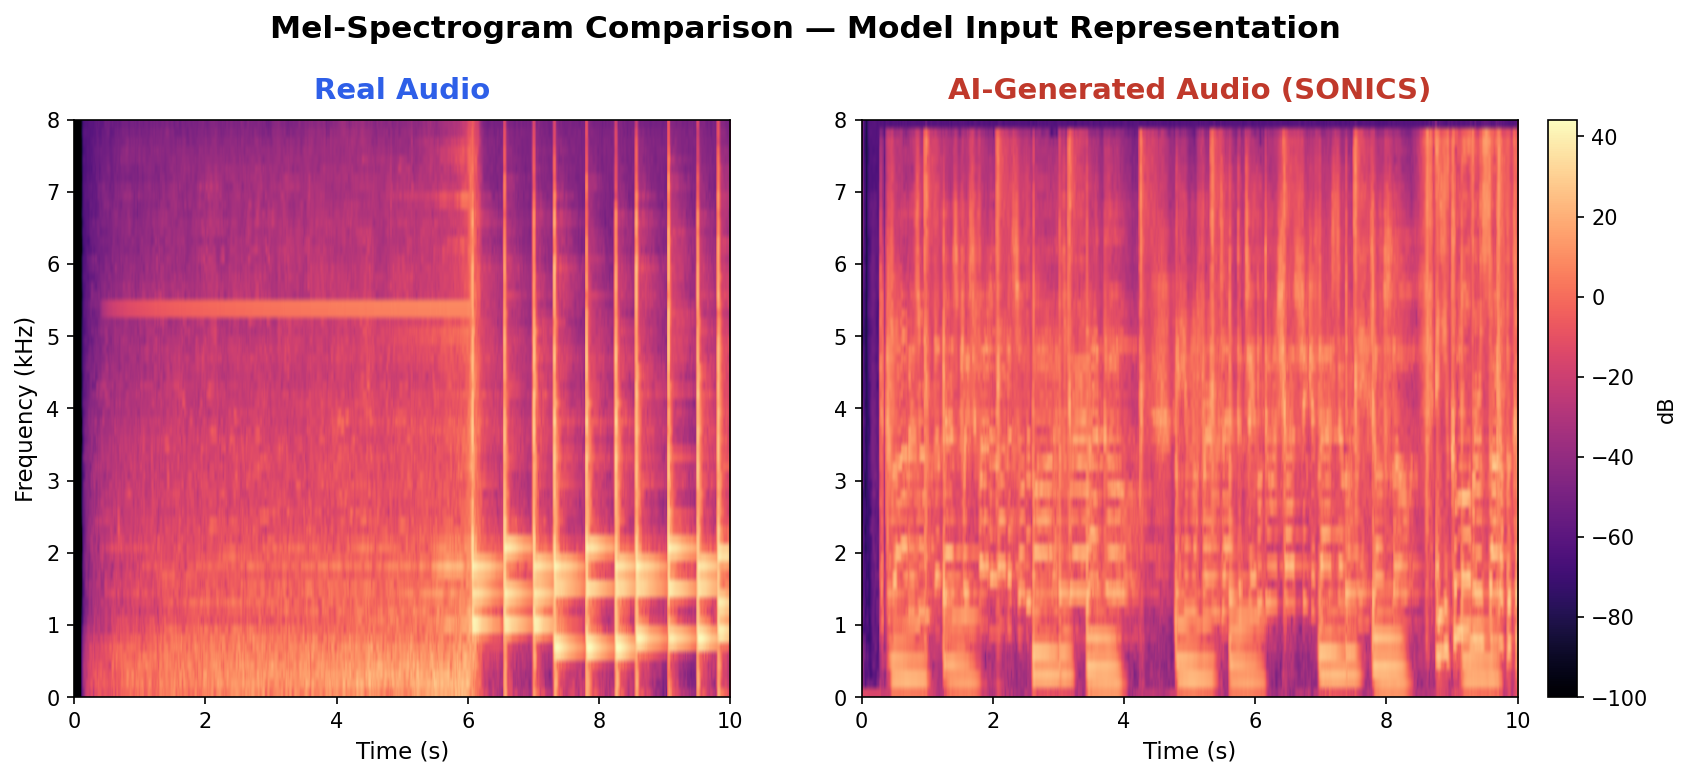

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np

# Pick one real and one fake clip from train_songs_df
real_example = train_songs_df[train_songs_df['label'] == 'real'].iloc[0]
fake_example = train_songs_df[train_songs_df['label'] == 'fake'].iloc[0]

real_clip_path = real_example['clip_filepath'][0]
fake_clip_path = fake_example['clip_filepath'][0]

def get_spectrogram_db(clip_path):
    waveform, sr = torchaudio.load(clip_path)
    if waveform.shape[0] > 1:
        waveform = waveform.mean(dim=0, keepdim=True)
    spec = amplitude_to_db(mel_transform(waveform))
    return spec.squeeze(0).numpy()

real_spec = get_spectrogram_db(real_clip_path)
fake_spec = get_spectrogram_db(fake_clip_path)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=150)

vmin = min(real_spec.min(), fake_spec.min())
vmax = max(real_spec.max(), fake_spec.max())

for ax, spec, title, color in [
    (axes[0], real_spec, "Real Audio", "#2E5FE8"),
    (axes[1], fake_spec, "AI-Generated Audio (SONICS)", "#C0392B"),
]:
    im = ax.imshow(spec, origin="lower", aspect="auto", cmap="magma", vmin=vmin, vmax=vmax,
                    extent=[0, 10, 0, TARGET_SR / 2 / 1000])
    ax.set_title(title, fontsize=14, fontweight="bold", color=color, pad=10)
    ax.set_xlabel("Time (s)", fontsize=11)
    ax.set_ylabel("Frequency (kHz)" if ax is axes[0] else "", fontsize=11)

fig.colorbar(im, ax=axes, orientation="vertical", fraction=0.025, pad=0.02, label="dB")
plt.suptitle("Mel-Spectrogram Comparison — Model Input Representation", fontsize=15, fontweight="bold", y=1.02)

save_path_drive = os.path.join(BASE_PATH, "reporting", "real_vs_fake_spectrogram.png")
plt.savefig(save_path_drive, bbox_inches="tight", facecolor="white")
print(f"Saved to: {save_path_drive}")
plt.show()